# Entrenar YOLO11s en el dataset unificado de cromosomas

1. **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU** (T4 en la versión gratis).
2. Ajusta `DRIVE_DATASET` en la celda de configuración: la carpeta que subiste a Drive (la que contiene `chromosome24/`), o un `.zip` de ella.
3. Ejecuta todo (**Entorno de ejecución → Ejecutar todas**).

**Segmentación (polígonos):** sube `unified_yolo/seg_labels.zip` a `MyDrive`, ejecuta antes `sam_54816_colab.ipynb` (genera los polígonos de 54816) y pon `TASK = 'segment'`.

Los pesos se guardan en Drive después de cada época. Si Colab se desconecta, vuelve a ejecutar todo: la celda de entrenamiento retoma desde `last.pt`.

In [ ]:
# === Configuración ===
DRIVE_DATASET = '/content/drive/MyDrive/DSP/Dataset'  # carpeta subida (con chromosome24/ dentro) o un .zip
VARIANT = 'chromosome24'   # 'chromosome24' (24 clases) o 'chromosome1' (una sola clase)
TASK = 'segment'            # 'detect' (cajas) o 'segment' (polígonos)
MODEL = 'yolo11s.pt' if TASK == 'detect' else 'yolo11s-seg.pt'
IMGSZ = 1024
EPOCHS = 100
RUNS_DIR = '/content/drive/MyDrive/yolo_runs'          # en Drive, para no perder los pesos si Colab se desconecta
RUN_NAME = f'{VARIANT}_{MODEL[:-3]}_{IMGSZ}'
LOCAL_DATA = '/content/data'                           # copia local: leer miles de archivos desde Drive es muy lento
# Solo para TASK = 'segment'
SEG_LABELS_EXACT = '/content/drive/MyDrive/DSP/Dataset/seg_labels.zip'   # polígonos de AutoKary y solapamientos (unified_yolo/seg_labels.zip)
SEG_LABELS_SAM = '/content/drive/MyDrive/DSP/Dataset/seg_labels_sam'     # polígonos de 54816, los escribe sam_54816_colab.ipynb

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
%pip install -q ultralytics

name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## Copiar el dataset al disco local de Colab

In [ ]:
import glob, os, re, shutil, subprocess

EXPECTED = {'chromosome24': (3880, 394, 1325), 'chromosome1': (4385, 464, 1398)}


def find_source():
    """Carpeta del variant o .zip en Drive; si DRIVE_DATASET no existe, busca en MyDrive."""
    p = DRIVE_DATASET.rstrip('/')
    if p.endswith('.zip') and os.path.isfile(p):
        return p
    if os.path.isfile(os.path.join(p, VARIANT, 'data.yaml')):
        return os.path.join(p, VARIANT)
    if os.path.isfile(os.path.join(p, 'data.yaml')):
        return p
    root = '/content/drive/MyDrive'
    hits = [os.path.dirname(f) for d in range(4) for f in glob.glob(f'{root}/{"*/" * d}{VARIANT}/data.yaml')]
    hits += [f for d in range(4) for f in glob.glob(f'{root}/{"*/" * d}*.zip')
             if re.search(r'unified|chromosome', os.path.basename(f), re.I)]
    if len(hits) == 1:
        return hits[0]
    raise FileNotFoundError(f'No encuentro {VARIANT} en {DRIVE_DATASET}. Candidatos: {hits or "ninguno"}. '
                            'Ajusta DRIVE_DATASET en la celda de configuración.')


def count(split):
    # Solo imágenes: cache='disk' deja un .npy junto a cada una
    imgs = [f for f in os.listdir(f'{DATA_DIR}/images/{split}') if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    return len(imgs), len(glob.glob(f'{DATA_DIR}/labels/{split}/*.txt'))


DATA_DIR = f'{LOCAL_DATA}/{VARIANT}'
if not (os.path.isdir(DATA_DIR) and all(count(s) == (n, n) for s, n in zip(('train', 'val', 'test'), EXPECTED[VARIANT]))):
    src = find_source()
    print('Copiando desde', src, '...')
    shutil.rmtree(DATA_DIR, ignore_errors=True)
    os.makedirs(LOCAL_DATA, exist_ok=True)
    if src.endswith('.zip'):
        subprocess.run(['unzip', '-q', '-o', src, '-d', LOCAL_DATA], check=True)
        found = glob.glob(f'{LOCAL_DATA}/**/{VARIANT}/data.yaml', recursive=True)
        if not found:
            raise FileNotFoundError(f'El zip no contiene {VARIANT}/data.yaml')
        if os.path.dirname(found[0]) != DATA_DIR:
            shutil.move(os.path.dirname(found[0]), DATA_DIR)
    else:
        subprocess.run(['cp', '-r', src, DATA_DIR], check=True)

    for f in glob.glob(f'{DATA_DIR}/labels/*.cache'):
        os.remove(f)

for split, n in zip(('train', 'val', 'test'), EXPECTED[VARIANT]):
    imgs, labels = count(split)
    ok = imgs == labels == n
    print(f'{split:5s}: {imgs} imágenes, {labels} etiquetas (esperado {n}) {"OK" if ok else "<-- FALTAN ARCHIVOS: revisa la subida a Drive"}')

with open(f'{DATA_DIR}/data.yaml') as fh:
    yaml_src = fh.read()

if TASK == 'segment':

    if not os.path.isfile(SEG_LABELS_EXACT):
        raise FileNotFoundError(f'Falta {SEG_LABELS_EXACT}: sube ahí unified_yolo/seg_labels.zip')
    exact = f'{LOCAL_DATA}/seg_labels/{VARIANT}'
    if not os.path.isdir(exact):
        subprocess.run(['unzip', '-q', '-o', SEG_LABELS_EXACT, '-d', LOCAL_DATA], check=True)
    SEG_DIR = f'{LOCAL_DATA}/{VARIANT}_seg'
    missing = []
    for split in ('train', 'val', 'test'):
        sam_dir = f'{SEG_LABELS_SAM}/{VARIANT}/{split}'
        sam_files = set(os.listdir(sam_dir)) if os.path.isdir(sam_dir) else set()
        for sub in ('images', 'labels'):
            os.makedirs(f'{SEG_DIR}/{sub}/{split}', exist_ok=True)
        for f in os.listdir(f'{DATA_DIR}/images/{split}'):
            if not f.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            stem = os.path.splitext(f)[0]
            if os.path.exists(f'{exact}/{split}/{stem}.txt'):
                src = f'{exact}/{split}/{stem}.txt'
            elif stem + '.txt' in sam_files:
                src = f'{sam_dir}/{stem}.txt'
            else:
                missing.append(f'{split}/{stem}')
                continue
            if not os.path.exists(f'{SEG_DIR}/images/{split}/{f}'):
                os.link(f'{DATA_DIR}/images/{split}/{f}', f'{SEG_DIR}/images/{split}/{f}')
            shutil.copy(src, f'{SEG_DIR}/labels/{split}/{stem}.txt')
    if missing:
        raise RuntimeError(f'{len(missing)} imágenes sin polígonos (p. ej. {missing[:3]}). '
                           '¿Terminó sam_54816_colab.ipynb?')
    print('Polígonos listos en', SEG_DIR)
    DATA_DIR = SEG_DIR

DATA_YAML = f'{DATA_DIR}/data_colab.yaml'
yaml_text = re.sub(r'(?m)^path:.*$', f'path: {DATA_DIR}', yaml_src)
with open(DATA_YAML, 'w') as fh:
    fh.write(yaml_text)
print(yaml_text.split('names:')[0])

Copiando desde /content/drive/MyDrive/DSP/Dataset/unified_yolo/chromosome1 ...
train: 4385 imágenes, 4385 etiquetas (esperado 4385) OK
val  : 464 imágenes, 464 etiquetas (esperado 464) OK
test : 1398 imágenes, 1398 etiquetas (esperado 1398) OK
Polígonos listos en /content/data/chromosome1_seg
# Built by tools/build_unified_yolo.py. Update `path` if you move the folder.
path: /content/data/chromosome1_seg
train: images/train
val: images/val
test: images/test
nc: 1



## Entrenar

In [ ]:
import torch

vram = torch.cuda.get_device_properties(0).total_memory / 2**30

BATCH = 32 if vram > 35 else 24 if vram > 20 else 16 if vram > 14 else 8
if TASK == 'segment':
    BATCH = max(4, BATCH * 3 // 4)
print(f'{torch.cuda.get_device_name(0)}: {vram:.0f} GB -> batch={BATCH}')
last = f'{RUNS_DIR}/{RUN_NAME}/weights/last.pt'

NVIDIA A100-SXM4-40GB: 39 GB -> batch=24


In [ ]:
finished = os.path.exists(last) and torch.load(last, map_location='cpu', weights_only=False).get('epoch', -1) == -1
if finished:
    print(f'{RUN_NAME} ya terminó. Para entrenar de nuevo cambia RUN_NAME.')
elif os.path.exists(last):
    print('Retomando desde', last)
    YOLO(last).train(resume=True, data=DATA_YAML)
else:
    YOLO(MODEL).train(
        data=DATA_YAML,
        imgsz=IMGSZ,
        epochs=EPOCHS,
        batch=BATCH,
        cache='disk',
        flipud=0.5,
        patience=30,

        **({'overlap_mask': False} if TASK == 'segment' else {}),
        project=RUNS_DIR,
        name=RUN_NAME,
        exist_ok=True,
    )

Retomando desde /content/drive/MyDrive/yolo_runs/chromosome1_yolo11s-seg_1024/weights/last.pt
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/chromosome1_seg/data_colab.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model

## Curvas de entrenamiento

In [ ]:
from IPython.display import Image, display

display(Image(filename=f'{RUNS_DIR}/{RUN_NAME}/results.png', width=1000))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/yolo_runs/chromosome24_yolo11s-seg_1024/results.png'

## Evaluar en test

In [ ]:
best = YOLO(f'{RUNS_DIR}/{RUN_NAME}/weights/best.pt')
metrics = best.val(data=DATA_YAML, split='test', imgsz=IMGSZ, batch=BATCH,
                   project=RUNS_DIR, name=f'{RUN_NAME}_test', exist_ok=True)
print(f'test  cajas     mAP50 = {metrics.box.map50:.3f}   mAP50-95 = {metrics.box.map:.3f}')
if TASK == 'segment':
    print(f'test  máscaras  mAP50 = {metrics.seg.map50:.3f}   mAP50-95 = {metrics.seg.map:.3f}')

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO11s-seg summary (fused): 113 layers, 10,076,104 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2076.6±550.0 MB/s, size: 104.0 KB)
val: Scanning /content/data/chromosome24_seg/labels/test... 1325 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1325/1325 378.2it/s 3.5s
val: New cache created: /content/data/chromosome24_seg/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 56/56 2.4it/s 23.2s
                   all       1325      60692       0.97      0.955      0.987      0.888      0.939      0.917      0.941      0.729
                     1       1324       2646      0.972      0.984      0.993      0.926      0.854       0.86      0.845      0.597
                     2       1325       2640      0.981       0.98      0.99

## Ver predicciones en algunas imágenes de test

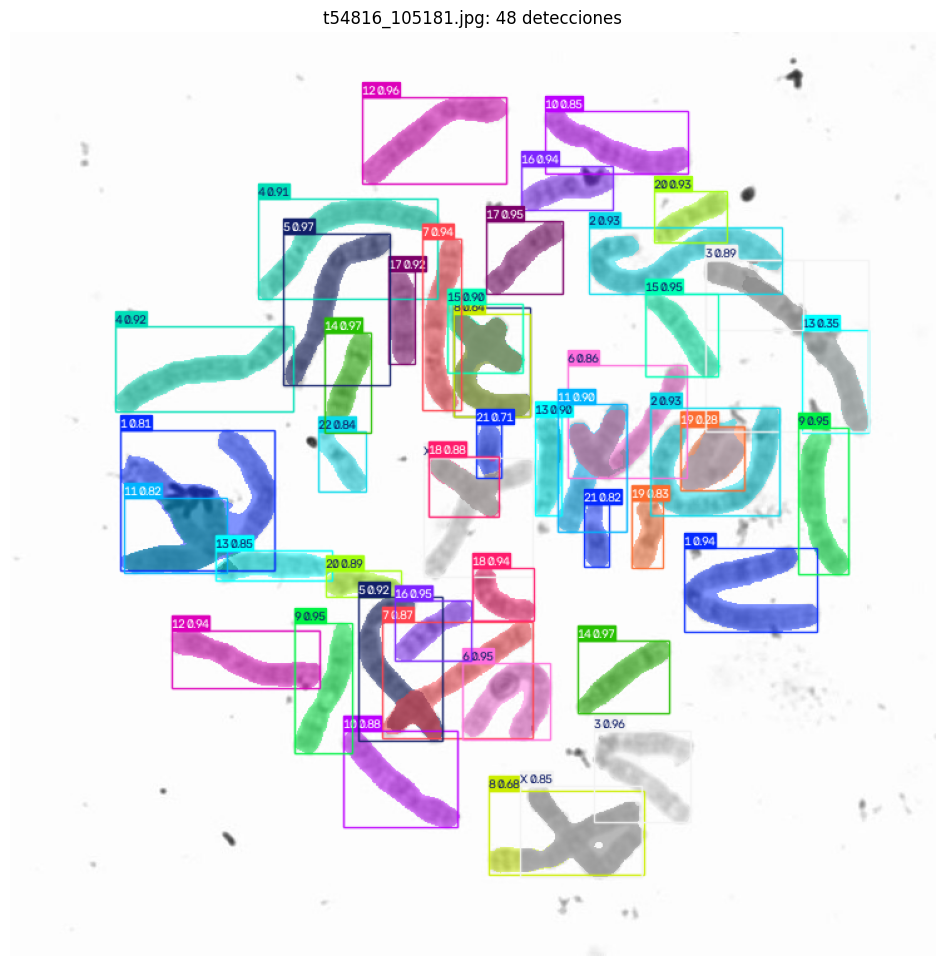

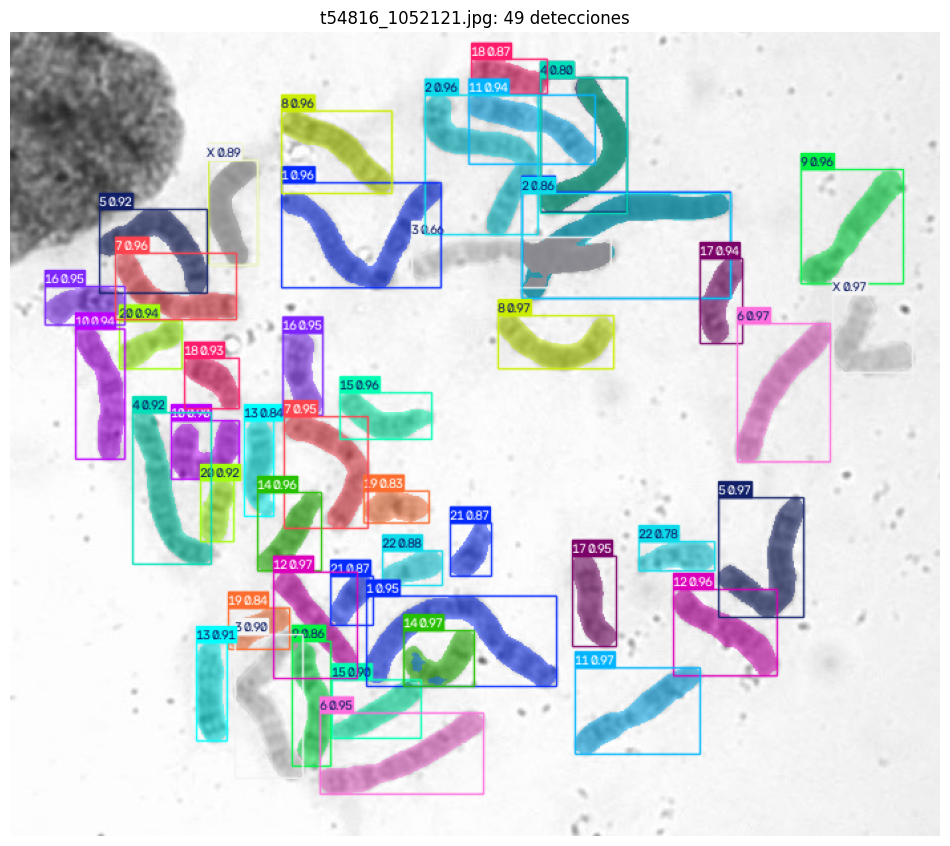

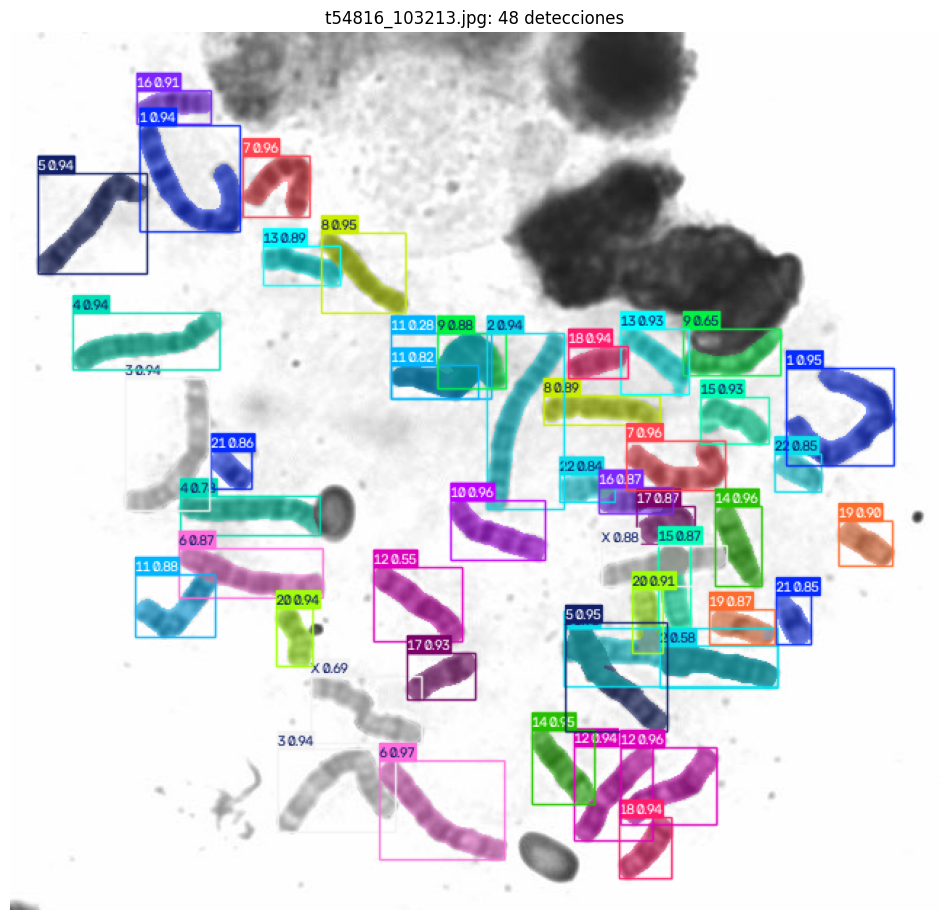

In [ ]:
import random
import matplotlib.pyplot as plt

random.seed(0)
test_imgs = sorted(f for f in glob.glob(f'{DATA_DIR}/images/test/*') if not f.endswith('.npy'))
for path in random.sample(test_imgs, min(3, len(test_imgs))):
    result = best.predict(path, imgsz=IMGSZ, conf=0.25, verbose=False)[0]
    plt.figure(figsize=(12, 12))
    plt.imshow(result.plot(line_width=1, font_size=8)[..., ::-1])
    plt.title(f'{os.path.basename(path)}: {len(result.boxes)} detecciones')
    plt.axis('off')
    plt.show()

In [ ]:
# Test solo con AutoKary (máscaras anotadas por personas)
auto = sorted(f for f in glob.glob(f'{DATA_DIR}/images/test/autokary_*') if not f.endswith('.npy'))
with open(f'{DATA_DIR}/test_autokary.txt', 'w') as fh:
    fh.write('\n'.join(auto) + '\n')
with open(DATA_YAML) as fh:
    yaml_auto = re.sub(r'(?m)^test:.*$', f'test: {DATA_DIR}/test_autokary.txt', fh.read())
with open(f'{DATA_DIR}/data_autokary.yaml', 'w') as fh:
    fh.write(yaml_auto)

m = best.val(data=f'{DATA_DIR}/data_autokary.yaml', split='test', imgsz=IMGSZ, batch=BATCH,
             project=RUNS_DIR, name=f'{RUN_NAME}_test_autokary', exist_ok=True)
print(f'AutoKary ({len(auto)} imágenes)  cajas mAP50 = {m.box.map50:.3f}   máscaras mAP50 = {m.seg.map50:.3f}  mAP50-95 = {m.seg.map:.3f}')

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5451.9±708.1 MB/s, size: 2353.3 KB)
val: Scanning /content/data/chromosome1_seg/labels/test... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 78.7it/s 1.0s
val: New cache created: /content/data/chromosome1_seg/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.0s/it 7.9s
                   all         75       3212      0.978      0.985      0.993      0.847      0.976      0.983      0.992      0.763
Speed: 9.5ms preprocess, 12.6ms inference, 0.0ms loss, 5.5ms postprocess per image
Results saved to /content/drive/MyDrive/yolo_runs/chromosome1_yolo11s-seg_1024_test_autokary
AutoKary (75 imágenes)  cajas mAP50 = 0.993 

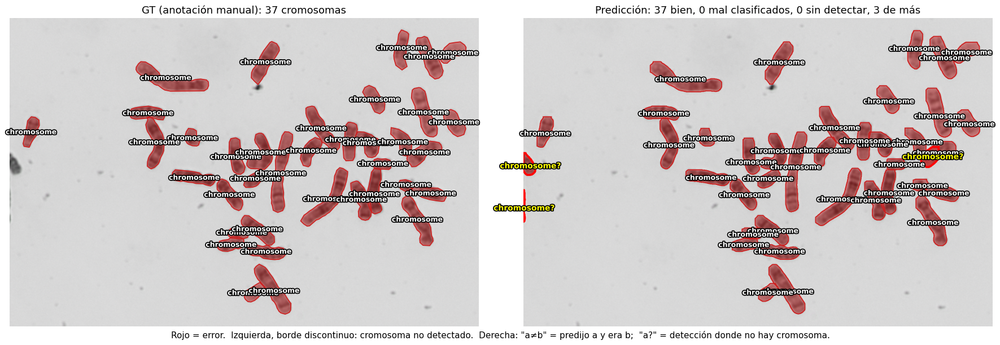

Guardada en /content/drive/MyDrive/yolo_runs/chromosome1_yolo11s-seg_1024_gt_vs_pred_autokary_211025-011C_110_2_737_345_0_468.png


In [ ]:
import colorsys
import glob, os, random
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Polygon
from PIL import Image as PILImage

FIG_IMAGE = 'None'
CONF = 0.25
NAMES = best.names  # {0: '1', ..., 22: 'X', 23: 'Y'}


def colour(k):
    """Un color por clase: los dos cromosomas de un par lo comparten."""
    return colorsys.hsv_to_rgb((k * 7 % 24) / 24, 0.85, 1.0 if k % 2 else 0.8)


def box(p):
    return p[:, 0].min(), p[:, 1].min(), p[:, 0].max(), p[:, 1].max()


def iou(a, b):
    iw = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    ih = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)


if TASK != 'segment':
    print("Esta figura compara máscaras: necesita TASK = 'segment'.")
else:
    test_imgs = sorted(f for f in glob.glob(f'{DATA_DIR}/images/test/autokary_*') if not f.endswith('.npy'))
    img_path = next((f for f in test_imgs if FIG_IMAGE and os.path.splitext(os.path.basename(f))[0] == FIG_IMAGE),
                    None) or random.choice(test_imgs)
    stem = os.path.splitext(os.path.basename(img_path))[0]
    img = np.asarray(PILImage.open(img_path).convert('RGB'))
    H, W = img.shape[:2]
    gt = []
    for line in open(f'{DATA_DIR}/labels/test/{stem}.txt'):
        v = line.split()
        gt.append((int(v[0]), np.array(v[1:], float).reshape(-1, 2) * [W, H]))
    r = best.predict(img_path, imgsz=IMGSZ, conf=CONF, retina_masks=True, verbose=False)[0]
    pred = [] if r.masks is None else [(int(c), np.asarray(xy, float))
                                       for c, xy in zip(r.boxes.cls.tolist(), r.masks.xy) if len(xy) >= 3]


    pairs = sorted(((iou(box(p), box(g)), i, j) for i, (_, p) in enumerate(pred) for j, (_, g) in enumerate(gt)),
                   reverse=True)
    match_p, match_g = {}, {}
    for v, i, j in pairs:
        if v < 0.5:
            break
        if i not in match_p and j not in match_g:
            match_p[i], match_g[j] = j, i
    ok = sum(pred[i][0] == gt[j][0] for i, j in match_p.items())
    wrong, missed, extra = len(match_p) - ok, len(gt) - len(match_g), len(pred) - len(match_p)

    pts = np.concatenate([p for _, p in gt + pred])
    (x0, y0), (x1, y1) = np.maximum(pts.min(0) - 40, 0), np.minimum(pts.max(0) + 40, [W, H])
    fig, axes = plt.subplots(1, 2, figsize=(18, 9 * (y1 - y0) / (x1 - x0) + 1.2))
    halo = [pe.withStroke(linewidth=2.5, foreground='black')]
    titles = [f'GT (anotación manual): {len(gt)} cromosomas',
              f'Predicción: {ok} bien, {wrong} mal clasificados, {missed} sin detectar, {extra} de más']
    for ax, title in zip(axes, titles):
        ax.imshow(img)
        ax.set_xlim(x0, x1)
        ax.set_ylim(y1, y0)
        ax.axis('off')
        ax.set_title(title, fontsize=13)
    for j, (k, p) in enumerate(gt):
        lost = j not in match_g
        axes[0].add_patch(Polygon(p, closed=True, facecolor=(*colour(k), 0.45), edgecolor='red' if lost else colour(k),
                                  lw=2.5 if lost else 1.2, ls='--' if lost else '-'))
        axes[0].text(*p.mean(0), NAMES[k], color='white', fontsize=9, ha='center', va='center', weight='bold',
                     path_effects=halo)
    for i, (k, p) in enumerate(pred):
        j = match_p.get(i)
        good = j is not None and gt[j][0] == k
        axes[1].add_patch(Polygon(p, closed=True, facecolor=(*colour(k), 0.45), edgecolor=colour(k) if good else 'red',
                                  lw=1.2 if good else 2.5))
        txt = NAMES[k] if good else f'{NAMES[k]}≠{NAMES[gt[j][0]]}' if j is not None else f'{NAMES[k]}?'
        axes[1].text(*p.mean(0), txt, color='white' if good else 'yellow', fontsize=9 if good else 10, ha='center',
                     va='center', weight='bold', path_effects=halo)
    plt.tight_layout()
    fig.text(0.5, axes[0].get_position().y0 - 0.01, 'Rojo = error.  Izquierda, borde discontinuo: cromosoma no '
             'detectado.  Derecha: "a≠b" = predijo a y era b;  "a?" = detección donde no hay cromosoma.',
             ha='center', va='top', fontsize=11)
    out = f'{RUNS_DIR}/{RUN_NAME}_gt_vs_pred_{stem}.png'
    #fig.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print('Guardada en', out)

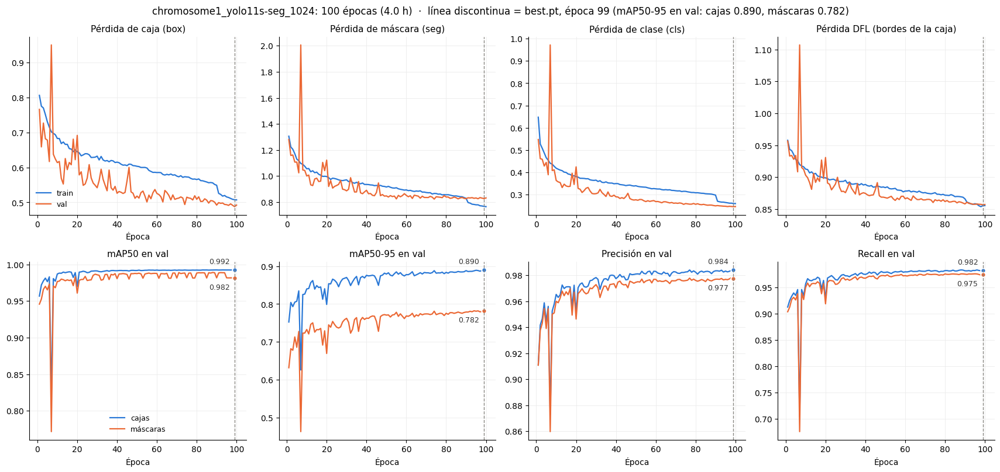

Guardada en /content/drive/MyDrive/yolo_runs/chromosome1_yolo11s-seg_1024_curvas.png


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#8a8984'

df = pd.read_csv(f'{RUNS_DIR}/{RUN_NAME}/results.csv')
df.columns = df.columns.str.strip()
ep = df['epoch']
seg = 'metrics/mAP50-95(M)' in df

fitness = df['metrics/mAP50-95(B)'] + (df['metrics/mAP50-95(M)'] if seg else 0)
b = int(fitness.values.argmax())

LOSSES = {'box_loss': 'Pérdida de caja (box)', 'seg_loss': 'Pérdida de máscara (seg)',
          'cls_loss': 'Pérdida de clase (cls)', 'dfl_loss': 'Pérdida DFL (bordes de la caja)'}

losses = [k for k in LOSSES if f'train/{k}' in df and df[f'train/{k}'].abs().max() > 0]
METRICS = [('mAP50', 'mAP50'), ('mAP50-95', 'mAP50-95'), ('precision', 'Precisión'), ('recall', 'Recall')]
ncols = max(len(losses), len(METRICS))
fig, axes = plt.subplots(2, ncols, figsize=(4.3 * ncols, 8.2), squeeze=False)


def style(ax, title):
    ax.set_title(title, fontsize=11)
    ax.axvline(ep[b], color=GRAY, ls='--', lw=1)
    ax.grid(color='0.92', lw=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_xlabel('Época')


for ax, k in zip(axes[0], losses):
    ax.plot(ep, df[f'train/{k}'], color=BLUE, lw=1.6, label='train')
    if f'val/{k}' in df:
        ax.plot(ep, df[f'val/{k}'], color=ORANGE, lw=1.6, label='val')
    style(ax, LOSSES[k])
for ax, (k, title) in zip(axes[1], METRICS):
    series = [('cajas', BLUE, df[f'metrics/{k}(B)'])] + ([('máscaras', ORANGE, df[f'metrics/{k}(M)'])] if seg else [])
    for name, colour, y in series:
        ax.plot(ep, y, color=colour, lw=1.6, label=name)

        ax.plot(ep[b], y[b], 'o', ms=6, color=colour, mec='white', mew=1.5)
        ax.annotate(f'{y[b]:.3f}', (ep[b], y[b]), xytext=(-6, 8 if colour == BLUE else -14), textcoords='offset points',
                    ha='right', fontsize=9, color='0.2')
    style(ax, f'{title} en val')
for ax in list(axes[0][len(losses):]) + list(axes[1][len(METRICS):]):
    ax.axis('off')
axes[0][0].legend(frameon=False, fontsize=9)
axes[1][0].legend(frameon=False, fontsize=9)

hours = df['time'].iloc[-1] / 3600 if 'time' in df else float('nan')
best_txt = f'cajas {df["metrics/mAP50-95(B)"][b]:.3f}' + (f', máscaras {df["metrics/mAP50-95(M)"][b]:.3f}' if seg else '')
fig.suptitle(f'{RUN_NAME}: {len(df)} épocas ({hours:.1f} h)  ·  línea discontinua = best.pt, época {ep[b]} '
             f'(mAP50-95 en val: {best_txt})', fontsize=12)
plt.tight_layout()
out = f'{RUNS_DIR}/{RUN_NAME}_curvas.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print('Guardada en', out)


73 recortes de test: 73 con cruce, 0 con cromosomas que solo se tocan
IoU por cromosoma: media 0.839, mediana 0.873
IoU del cruce:     media 0.391, mediana 0.308
Número de cromosomas predichos: igual al GT en 51, menos en 1 (fusionados o perdidos), más en 21


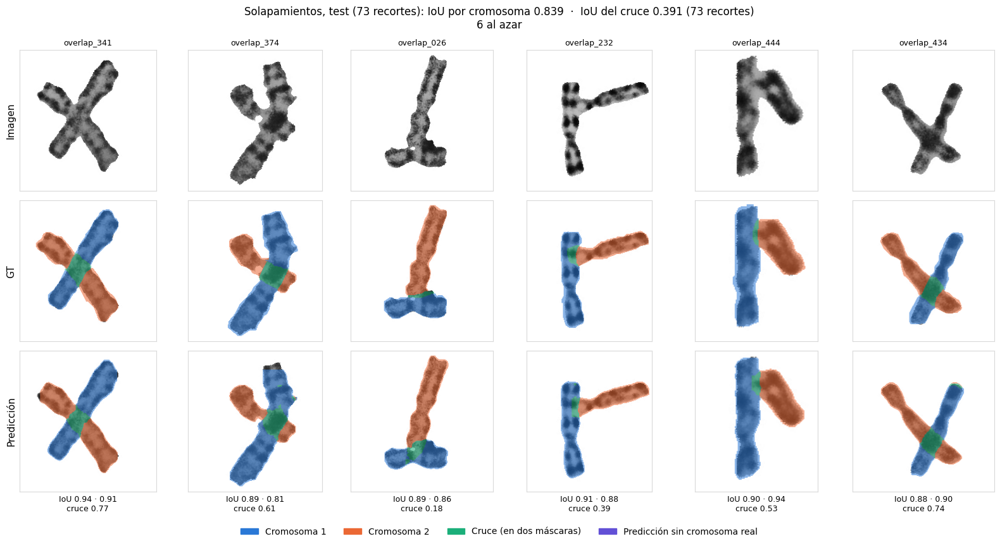

Guardada en /content/drive/MyDrive/yolo_runs/chromosome1_yolo11s-seg_1024_overlap_test.png


In [ ]:
import glob, os, random
import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from PIL import Image as PILImage, ImageDraw

N_SHOW = 6
SHOW = 'azar'
CONF = 0.25
MIN_CROSS = 0.02
COLOURS = ['#2a78d6', '#eb6834']
CROSS, EXTRA = '#1baf7a', '#6250d6'


def rgb(h):
    return np.array([int(h[i:i + 2], 16) for i in (1, 3, 5)]) / 255


def mask_iou(a, b):
    union = (a | b).sum()
    return (a & b).sum() / union if union else 0.0


def overlay(img, masks, colours, cross):
    base = img / 255
    out = base.copy()
    for m, c in zip(masks, colours):
        out[m] = 0.45 * base[m] + 0.55 * rgb(c)
    out[cross] = 0.45 * base[cross] + 0.55 * rgb(CROSS)
    return out


imgs = sorted(f for f in glob.glob(f'{DATA_DIR}/images/test/overlap_*') if not f.endswith('.npy'))
if TASK != 'segment' or not imgs:
    print("Necesita TASK = 'segment' y VARIANT = 'chromosome1' (los recortes de solapamientos solo están ahí).")
else:
    rows = []
    for path in imgs:
        stem = os.path.splitext(os.path.basename(path))[0]
        img = np.asarray(PILImage.open(path).convert('RGB'))
        H, W = img.shape[:2]
        gt = []
        for line in open(f'{DATA_DIR}/labels/test/{stem}.txt'):
            p = np.array(line.split()[1:], float).reshape(-1, 2) * [W, H]
            m = PILImage.new('1', (W, H), 0)
            ImageDraw.Draw(m).polygon([tuple(q) for q in p], fill=1)
            gt.append(np.asarray(m))
        r = best.predict(path, imgsz=IMGSZ, conf=CONF, retina_masks=True, verbose=False)[0]
        pred = [] if r.masks is None else [
            cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST) > 0
            for m in r.masks.data.cpu().numpy() > 0.5]

        # Cada cromosoma real se empareja con la máscara predicha que más se le parece (IoU de máscaras, de mayor a menor)
        ious = np.array([[mask_iou(g, p) for p in pred] for g in gt]).reshape(len(gt), len(pred))
        match = {}
        for v, j, i in sorted(((ious[j, i], j, i) for j in range(len(gt)) for i in range(len(pred))), reverse=True):
            if v > 0 and j not in match and i not in match.values():
                match[j] = i
        chrom = [ious[j, match[j]] if j in match else 0.0 for j in range(len(gt))]
        # Cruce = píxeles dentro de dos o más máscaras, en el GT y en la predicción
        gt_cross = np.sum(gt, 0) >= 2
        pred_cross = np.sum(pred, 0) >= 2 if len(pred) >= 2 else np.zeros_like(gt_cross)
        crossing = gt_cross.sum() >= MIN_CROSS * min(g.sum() for g in gt)
        rows.append(dict(stem=stem, img=img, gt=gt, pred=pred, match=match, chrom=chrom, gt_cross=gt_cross,
                         pred_cross=pred_cross, cross=mask_iou(gt_cross, pred_cross) if crossing else None))

    chrom_all = [v for r in rows for v in r['chrom']]
    crosses = [r['cross'] for r in rows if r['cross'] is not None]
    n_ok = sum(len(r['pred']) == len(r['gt']) for r in rows)
    n_less = sum(len(r['pred']) < len(r['gt']) for r in rows)
    print(f'{len(rows)} recortes de test: {len(crosses)} con cruce, {len(rows) - len(crosses)} con cromosomas que solo '
          f'se tocan')
    print(f'IoU por cromosoma: media {np.mean(chrom_all):.3f}, mediana {np.median(chrom_all):.3f}')
    if crosses:
        print(f'IoU del cruce:     media {np.mean(crosses):.3f}, mediana {np.median(crosses):.3f}')
    print(f'Número de cromosomas predichos: igual al GT en {n_ok}, menos en {n_less} (fusionados o perdidos), '
          f'más en {len(rows) - n_ok - n_less}')

    score = lambda r: np.mean(r['chrom'] + ([r['cross']] if r['cross'] is not None else []))
    random.seed(0)
    shown = (sorted(rows, key=score) if SHOW == 'peores' else random.sample(rows, len(rows)))[:N_SHOW]
    fig, axes = plt.subplots(3, len(shown), figsize=(2.7 * len(shown), 8.6), squeeze=False)
    for c, r in enumerate(shown):
        owner = {i: j for j, i in r['match'].items()}
        panels = [r['img'] / 255, overlay(r['img'], r['gt'], COLOURS, r['gt_cross']),
                  overlay(r['img'], r['pred'], [COLOURS[owner[i]] if i in owner else EXTRA
                                                for i in range(len(r['pred']))], r['pred_cross'])]
        for ax, panel in zip(axes[:, c], panels):
            ax.imshow(panel)
            ax.set_xticks([])
            ax.set_yticks([])
            for s in ax.spines.values():
                s.set_color('0.85')
        axes[0, c].set_title(r['stem'], fontsize=9)
        txt = ' · '.join(f'{v:.2f}' for v in r['chrom'])
        txt += f'\ncruce {r["cross"]:.2f}' if r['cross'] is not None else '\nsolo se tocan'
        axes[2, c].set_xlabel(f'IoU {txt}', fontsize=9)
    for ax, label in zip(axes[:, 0], ['Imagen', 'GT', 'Predicción']):
        ax.set_ylabel(label, fontsize=11)
    fig.legend(handles=[Patch(color=COLOURS[0], label='Cromosoma 1'), Patch(color=COLOURS[1], label='Cromosoma 2'),
                        Patch(color=CROSS, label='Cruce (en dos máscaras)'),
                        Patch(color=EXTRA, label='Predicción sin cromosoma real')],
               loc='lower center', ncol=4, frameon=False, fontsize=10, bbox_to_anchor=(0.5, -0.01))
    summary = (f'IoU por cromosoma {np.mean(chrom_all):.3f}' +
               (f'  ·  IoU del cruce {np.mean(crosses):.3f} ({len(crosses)} recortes)' if crosses else ''))
    fig.suptitle(f'Solapamientos, test ({len(rows)} recortes): {summary}\n'
                 f'{"Los " + str(len(shown)) + " peores" if SHOW == "peores" else str(len(shown)) + " al azar"}',
                 fontsize=12)
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    out = f'{RUNS_DIR}/{RUN_NAME}_overlap_test.png'
    fig.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print('Guardada en', out)


In [ ]:

CANVAS_ZIP = '/content/drive/MyDrive/DSP/Dataset/overlap_canvases.zip'   # unified_yolo/overlap_canvases.zip
BASE_RUN = 'chromosome1_yolo11s-seg_1024'                     # el modelo ya entrenado
ADD_CANVASES = True   # False = control: el mismo ajuste fino sin lienzos, para separar su efecto del de entrenar más
FT_EPOCHS = 40
FT_RUN = f'{BASE_RUN}_ft_' + ('lienzos' if ADD_CANVASES else 'control')
CROPS_DIR = f'{LOCAL_DATA}/chromosome1_seg'
CANVAS_DIR = f'{LOCAL_DATA}/overlap_canvases'
FT_DIR = f'{LOCAL_DATA}/{FT_RUN}'

In [ ]:
# Ajuste fino del modelo chromosome1 con los lienzos de solapamientos (recortes pegados a su tamaño real en 1024 px).
# Antes: ejecuta las celdas de datos con VARIANT = 'chromosome1' y TASK = 'segment', y la celda de BATCH.
import os, shutil, subprocess
import torch
from ultralytics import YOLO


if not os.path.isdir(f'{CROPS_DIR}/labels/train'):
    raise RuntimeError("Falta chromosome1_seg: ejecuta antes las celdas de datos con VARIANT='chromosome1', TASK='segment'")
if not os.path.isdir(CANVAS_DIR):
    subprocess.run(['unzip', '-q', '-o', CANVAS_ZIP, '-d', LOCAL_DATA], check=True)

# Mismas imágenes que chromosome1 (enlaces duros: no ocupan espacio) más los lienzos de train y val.
# El test no cambia, para comparar con el modelo base; los lienzos de test se usan en la celda de comparación.
for split in ('train', 'val', 'test'):
    for sub in ('images', 'labels'):
        os.makedirs(f'{FT_DIR}/{sub}/{split}', exist_ok=True)
    for src in [CROPS_DIR] + ([CANVAS_DIR] if ADD_CANVASES and split != 'test' else []):
        for f in os.listdir(f'{src}/images/{split}'):
            stem, ext = os.path.splitext(f)
            # .npy = caché de cache='disk' ya hecha para chromosome1 (mismo imgsz): se reutiliza en vez de rehacerla
            if ext.lower() not in ('.jpg', '.jpeg', '.png', '.npy'):
                continue
            if not os.path.exists(f'{FT_DIR}/images/{split}/{f}'):
                os.link(f'{src}/images/{split}/{f}', f'{FT_DIR}/images/{split}/{f}')
            if ext.lower() != '.npy':
                shutil.copy(f'{src}/labels/{split}/{stem}.txt', f'{FT_DIR}/labels/{split}/{stem}.txt')
    n = len([f for f in os.listdir(f'{FT_DIR}/images/{split}') if not f.endswith('.npy')])
    n_canvas = len([f for f in os.listdir(f'{FT_DIR}/images/{split}') if f.startswith('canvas_') and not f.endswith('.npy')])
    print(f'{split:5s}: {n} imágenes ({n_canvas} lienzos)')

FT_YAML = f'{FT_DIR}/data_colab.yaml'
with open(FT_YAML, 'w') as fh:
    fh.write(f"path: {FT_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\nnc: 1\nnames:\n  0: 'chromosome'\n")

last = f'{RUNS_DIR}/{FT_RUN}/weights/last.pt'
finished = os.path.exists(last) and torch.load(last, map_location='cpu', weights_only=False).get('epoch', -1) == -1
if finished:
    print(f'{FT_RUN} ya terminó.')
elif os.path.exists(last):
    print('Retomando desde', last)
    YOLO(last).train(resume=True, data=FT_YAML)
else:
    YOLO(f'{RUNS_DIR}/{BASE_RUN}/weights/best.pt').train(
        data=FT_YAML,
        imgsz=IMGSZ,
        epochs=FT_EPOCHS,
        batch=BATCH,
        cache='disk',
        flipud=0.5,
        patience=15,
        overlap_mask=False,
        # El modelo ya está entrenado: learning rate 5 veces menor que el inicial y un solo epoch de calentamiento.
        # Se fija optimizer='SGD' porque con 'auto' Ultralytics ignora lr0.
        optimizer='SGD',
        lr0=0.002,
        warmup_epochs=1,
        project=RUNS_DIR,
        name=FT_RUN,
        exist_ok=True,
    )

# Las celdas siguientes (curvas, test, solapamientos...) pasan a usar el modelo ajustado
RUN_NAME, DATA_DIR, DATA_YAML = FT_RUN, FT_DIR, FT_YAML

RuntimeError: Falta chromosome1_seg: ejecuta antes las celdas de datos con VARIANT='chromosome1', TASK='segment'

Ajuste sin lienzos: no existe /content/drive/MyDrive/yolo_runs/chromosome1_yolo11s-seg_1024_ft_control/weights/best.pt, se omite

73 recortes de test, modo lienzos
modelo               IoU crom. IoU cruce   cruce <10 % cruce 10-20 %  cruce >=20 %  cruce (píxeles juntos)   nº máscaras igual/menos/más que el GT
Base                     0.381     0.079    0.030 (18)    0.007 (13)    0.122 (42)                   0.171   22/49/2
Ajuste con lienzos       0.834     0.440    0.275 (18)    0.245 (13)    0.571 (42)                   0.409   58/3/12


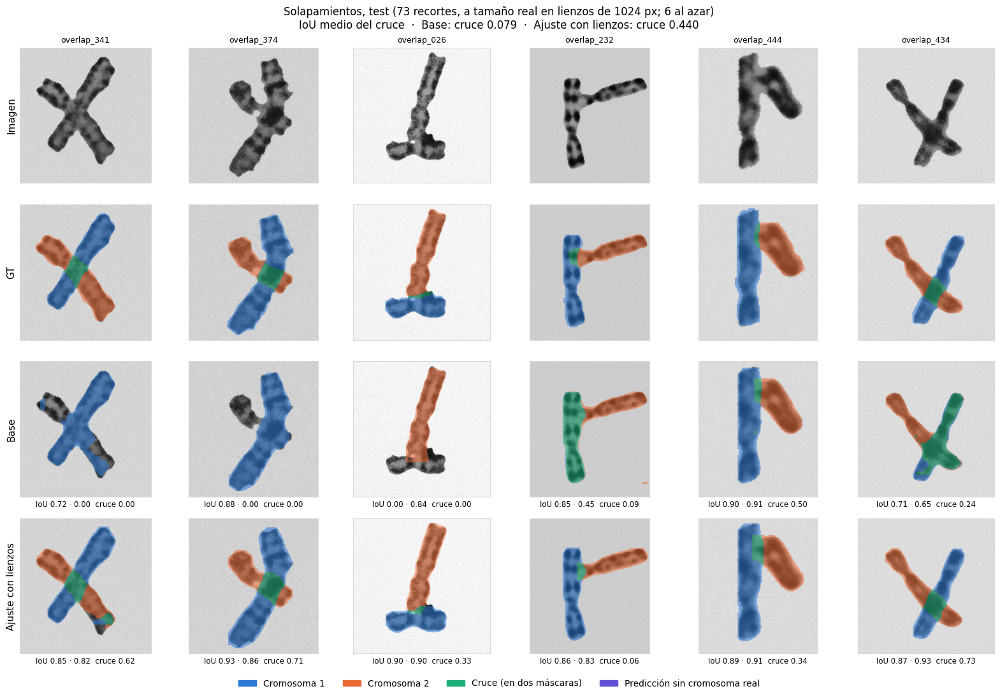

Guardada en /content/drive/MyDrive/yolo_runs/overlap_compare_lienzos.png


In [ ]:
# Solapamientos: compara modelos en los 73 recortes de test, con el IoU de cada cromosoma y el del cruce.
# MODE = 'lienzos':  cada recorte a su tamaño real dentro de un lienzo de 1024 px, como estaría en una metafase.
# MODE = 'recortes': cada recorte solo, que Ultralytics amplía a 1024 px (como la celda anterior de solapamientos).
import csv, glob, os, random, subprocess
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from PIL import Image as PILImage, ImageDraw
from ultralytics import YOLO

MODELS = {
    'Base': f'{RUNS_DIR}/chromosome1_yolo11s-seg_1024/weights/best.pt',
    'Ajuste sin lienzos': f'{RUNS_DIR}/chromosome1_yolo11s-seg_1024_ft_control/weights/best.pt',
    'Ajuste con lienzos': f'{RUNS_DIR}/chromosome1_yolo11s-seg_1024_ft_lienzos/weights/best.pt',
}
MODE = 'lienzos'    # 'lienzos' o 'recortes'
N_SHOW = 6          # recortes en la figura
SHOW = 'azar'       # 'azar' o 'peores' (los de menor IoU con el primer modelo)
CONF = 0.25
MIN_CROSS = 0.02
CROPS_DIR = f'{LOCAL_DATA}/chromosome1_seg'
CANVAS_DIR = f'{LOCAL_DATA}/overlap_canvases'
CANVAS_ZIP = '/content/drive/MyDrive/DSP/Dataset/overlap_canvases.zip'
COLOURS = ['#2a78d6', '#eb6834']  # cromosoma 1, cromosoma 2
CROSS, EXTRA = '#1baf7a', '#6250d6'


def rgb(h):
    return np.array([int(h[i:i + 2], 16) for i in (1, 3, 5)]) / 255


def mask_iou(a, b):
    union = (a | b).sum()
    return (a & b).sum() / union if union else 0.0


def overlay(img, masks, colours, cross):
    base = img / 255
    out = base.copy()
    for m, c in zip(masks, colours):
        out[m] = 0.45 * base[m] + 0.55 * rgb(c)
    out[cross] = 0.45 * base[cross] + 0.55 * rgb(CROSS)
    return out


def predict_masks(model, path):
    r = model.predict(path, imgsz=IMGSZ, conf=CONF, retina_masks=True, verbose=False)[0]
    if r.masks is None:
        return []
    H, W = r.orig_shape
    return [m if m.shape == (H, W) else np.asarray(PILImage.fromarray(m).resize((W, H), PILImage.NEAREST))
            for m in r.masks.data.cpu().numpy() > 0.5]


def evaluate(gt, pred):
    """Empareja cada cromosoma real con la máscara predicha que más se le parece y mide los IoU."""
    ious = np.array([[mask_iou(g, p) for p in pred] for g in gt]).reshape(len(gt), len(pred))
    match = {}
    for v, j, i in sorted(((ious[j, i], j, i) for j in range(len(gt)) for i in range(len(pred))), reverse=True):
        if v > 0 and j not in match and i not in match.values():
            match[j] = i
    gt_cross = np.sum(gt, 0) >= 2
    pred_cross = np.sum(pred, 0) >= 2 if len(pred) >= 2 else np.zeros_like(gt_cross)
    share = gt_cross.sum() / min(g.sum() for g in gt)
    return dict(pred=pred, match=match, chrom=[ious[j, match[j]] if j in match else 0.0 for j in range(len(gt))],
                pred_cross=pred_cross, share=share,
                cross=mask_iou(gt_cross, pred_cross) if share >= MIN_CROSS else None)


models = {}
for name, path in MODELS.items():
    if os.path.exists(path):
        models[name] = YOLO(path)
    else:
        print(f'{name}: no existe {path}, se omite')
if not models:
    raise FileNotFoundError('Ninguno de los modelos de MODELS existe todavía')

crops = {}
for path in sorted(f for f in glob.glob(f'{CROPS_DIR}/images/test/overlap_*') if not f.endswith('.npy')):
    stem = os.path.splitext(os.path.basename(path))[0]
    img = np.asarray(PILImage.open(path).convert('RGB'))
    H, W = img.shape[:2]
    gt = []
    for line in open(f'{CROPS_DIR}/labels/test/{stem}.txt'):
        p = np.array(line.split()[1:], float).reshape(-1, 2) * [W, H]
        m = PILImage.new('1', (W, H), 0)
        ImageDraw.Draw(m).polygon([tuple(q) for q in p], fill=1)
        gt.append(np.asarray(m))
    crops[stem] = dict(path=path, img=img, gt=gt, gt_cross=np.sum(gt, 0) >= 2)

results = {name: {} for name in models}
if MODE == 'lienzos':
    if not os.path.isdir(CANVAS_DIR):
        subprocess.run(['unzip', '-q', '-o', CANVAS_ZIP, '-d', os.path.dirname(CANVAS_DIR)], check=True)
    by_canvas = {}
    for row in csv.DictReader(open(f'{CANVAS_DIR}/placements.csv')):
        if row['split'] == 'test':
            by_canvas.setdefault(row['canvas'], []).append(row)
    for canvas, places in by_canvas.items():
        path = f'{CANVAS_DIR}/images/test/{canvas}.jpg'
        canvas_img = np.asarray(PILImage.open(path).convert('RGB'))
        masks = {name: predict_masks(model, path) for name, model in models.items()}
        for row in places:
            c = crops[row['crop']]
            x0, y0, w, h = (int(row[k]) for k in ('x0', 'y0', 'w', 'h'))
            assert (h, w) == c['img'].shape[:2], 'los lienzos de test deben tener los recortes a escala 1'
            c['img'] = canvas_img[y0:y0 + h, x0:x0 + w]  # el recorte tal como lo ve el modelo en el lienzo
            for name in models:

                pred = [m[y0:y0 + h, x0:x0 + w] for m in masks[name]]
                pred = [r for m, r in zip(masks[name], pred) if r.any() and r.sum() >= 0.5 * m.sum()]
                results[name][row['crop']] = evaluate(c['gt'], pred)
else:
    for stem, c in crops.items():
        for name, model in models.items():
            results[name][stem] = evaluate(c['gt'], predict_masks(model, c['path']))


SIZES = [('<10 %', 0, 0.1), ('10-20 %', 0.1, 0.2), ('>=20 %', 0.2, 2)]
print(f'\n{len(crops)} recortes de test, modo {MODE}')
print(f'{"modelo":20s} {"IoU crom.":>9s} {"IoU cruce":>9s} ' + ' '.join(f'{"cruce " + s:>13s}' for s, _, _ in SIZES) +
      f' {"cruce (píxeles juntos)":>23s}   nº máscaras igual/menos/más que el GT')
for name, res in results.items():
    rs = [(crops[s], r) for s, r in res.items()]
    chrom = np.mean([v for _, r in rs for v in r['chrom']])
    cross = [r['cross'] for _, r in rs if r['cross'] is not None]
    by_size = []
    for _, lo, hi in SIZES:
        sel = [r['cross'] for _, r in rs if r['cross'] is not None and lo <= r['share'] < hi]
        by_size.append(f'{np.mean(sel):.3f} ({len(sel):2d})' if sel else '-')
    pooled = (sum((c['gt_cross'] & r['pred_cross']).sum() for c, r in rs) /
              max(sum((c['gt_cross'] | r['pred_cross']).sum() for c, r in rs), 1))
    n_eq = sum(len(r['pred']) == len(c['gt']) for c, r in rs)
    n_less = sum(len(r['pred']) < len(c['gt']) for c, r in rs)
    print(f'{name:20s} {chrom:9.3f} {np.mean(cross):9.3f} ' + ' '.join(f'{s:>13s}' for s in by_size) +
          f' {pooled:23.3f}   {n_eq}/{n_less}/{len(rs) - n_eq - n_less}')


names = list(results)
score = lambda stem: np.mean(results[names[0]][stem]['chrom'] + ([results[names[0]][stem]['cross']]
                                                                 if results[names[0]][stem]['cross'] is not None else []))
random.seed(0)
shown = (sorted(crops, key=score) if SHOW == 'peores' else random.sample(list(crops), len(crops)))[:N_SHOW]
fig, axes = plt.subplots(2 + len(names), len(shown), figsize=(2.7 * len(shown), 2.75 * (2 + len(names))),
                         squeeze=False)
for col, stem in enumerate(shown):
    c = crops[stem]
    panels = [c['img'] / 255, overlay(c['img'], c['gt'], COLOURS, c['gt_cross'])]
    for name in names:
        r = results[name][stem]
        owner = {i: j for j, i in r['match'].items()}
        panels.append(overlay(c['img'], r['pred'], [COLOURS[owner[i]] if i in owner else EXTRA
                                                    for i in range(len(r['pred']))], r['pred_cross']))
    for ax, panel in zip(axes[:, col], panels):
        ax.imshow(panel)
        ax.set_xticks([])
        ax.set_yticks([])
        for s in ax.spines.values():
            s.set_color('0.85')
    axes[0, col].set_title(stem, fontsize=9)
    for ax, name in zip(axes[2:, col], names):
        r = results[name][stem]
        txt = ' · '.join(f'{v:.2f}' for v in r['chrom'])
        txt += f'  cruce {r["cross"]:.2f}' if r['cross'] is not None else ''
        ax.set_xlabel(f'IoU {txt}', fontsize=8.5)
for ax, label in zip(axes[:, 0], ['Imagen', 'GT'] + names):
    ax.set_ylabel(label, fontsize=11)
fig.legend(handles=[Patch(color=COLOURS[0], label='Cromosoma 1'), Patch(color=COLOURS[1], label='Cromosoma 2'),
                    Patch(color=CROSS, label='Cruce (en dos máscaras)'),
                    Patch(color=EXTRA, label='Predicción sin cromosoma real')],
           loc='lower center', ncol=4, frameon=False, fontsize=10, bbox_to_anchor=(0.5, -0.005))
summary = '  ·  '.join(f'{n}: cruce {np.mean([r["cross"] for r in results[n].values() if r["cross"] is not None]):.3f}'
                       for n in names)
where = 'a tamaño real en lienzos de 1024 px' if MODE == 'lienzos' else 'cada recorte ampliado a 1024 px'
fig.suptitle(f'Solapamientos, test ({len(crops)} recortes, {where}; '
             f'{"los " + str(len(shown)) + " peores del primer modelo" if SHOW == "peores" else str(len(shown)) + " al azar"})'
             f'\nIoU medio del cruce  ·  {summary}', fontsize=12)
plt.tight_layout(rect=(0, 0.025, 1, 1))
out = f'{RUNS_DIR}/overlap_compare_{MODE}.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print('Guardada en', out)

In [ ]:
# chromosome24 (24 clases, segmentación) partiendo del modelo de segmentación chromosome1 en vez de COCO.
# Antes: ejecuta las celdas de datos con VARIANT = 'chromosome24' y TASK = 'segment', y la celda de BATCH.
# Ultralytics carga todos los pesos que encajan (backbone, cuello y máscaras); solo la capa final de clasificación,
# que pasa de 1 a 24 clases, empieza de cero.
import os
import torch
from ultralytics import YOLO

SEG_RUN = 'chromosome1_yolo11s-seg_1024'          # el modelo de segmentación de partida
C24_RUN = 'chromosome24_yolo11s-seg_1024_desde_c1'
SEG24 = f'{LOCAL_DATA}/chromosome24_seg'
SEG24_YAML = f'{SEG24}/data_colab.yaml'

if not os.path.exists(SEG24_YAML):
    raise RuntimeError("Falta chromosome24_seg: ejecuta antes las celdas de datos con VARIANT='chromosome24', "
                       "TASK='segment'")
with open(SEG24_YAML) as fh:
    assert 'nc: 24' in fh.read(), f'{SEG24_YAML} no es el dataset de 24 clases'

last = f'{RUNS_DIR}/{C24_RUN}/weights/last.pt'
finished = os.path.exists(last) and torch.load(last, map_location='cpu', weights_only=False).get('epoch', -1) == -1
if finished:
    print(f'{C24_RUN} ya terminó.')
elif os.path.exists(last):
    print('Retomando desde', last)
    YOLO(last).train(resume=True, data=SEG24_YAML)
else:
    # Mismos ajustes que el chromosome24 entrenado desde COCO, para que la comparación solo cambie el punto de partida
    YOLO(f'{RUNS_DIR}/{SEG_RUN}/weights/best.pt').train(
        data=SEG24_YAML,
        imgsz=IMGSZ,
        epochs=100,
        batch=BATCH,
        cache='disk',
        flipud=0.5,
        patience=30,
        overlap_mask=False,
        project=RUNS_DIR,
        name=C24_RUN,
        exist_ok=True,
    )

# Las celdas siguientes (curvas, test, matriz de confusión, figura GT vs predicción) pasan a usar este modelo
RUN_NAME, DATA_DIR, DATA_YAML = C24_RUN, SEG24, SEG24_YAML

In [ ]:
DRIVE_DATASET = '/content/drive/MyDrive/DSP/Dataset'  # carpeta subida (con chromosome24/ dentro) o un .zip
VARIANT = 'chromosome24'   # 'chromosome24' (24 clases) o 'chromosome1' (una sola clase)
TASK = 'segment'            # 'detect' (cajas) o 'segment' (polígonos)
MODEL = 'yolo11s.pt' if TASK == 'detect' else 'yolo11s-seg.pt'
IMGSZ = 1024
EPOCHS = 100
RUNS_DIR = '/content/drive/MyDrive/yolo_runs'          # en Drive, para no perder los pesos si Colab se desconecta
RUN_NAME = f'{VARIANT}_{MODEL[:-3]}_{IMGSZ}'
LOCAL_DATA = '/content/data'                           # copia local: leer miles de archivos desde Drive es muy lento
# Solo para TASK = 'segment'
SEG_LABELS_EXACT = '/content/drive/MyDrive/DSP/Dataset/seg_labels.zip'   # polígonos de AutoKary y solapamientos (unified_yolo/seg_labels.zip)
SEG_LABELS_SAM = '/content/drive/MyDrive/DSP/Dataset/seg_labels_sam'

In [ ]:
# chromosome24 (24 clases, segmentación) partiendo del modelo de segmentación chromosome1 en vez de COCO.
# Antes: ejecuta las celdas de datos con VARIANT = 'chromosome24' y TASK = 'segment', y la celda de BATCH.
# Ultralytics carga todos los pesos que encajan (backbone, cuello y máscaras); solo la capa final de clasificación,
# que pasa de 1 a 24 clases, empieza de cero.
import os
import torch
from ultralytics import YOLO

SEG_RUN = 'chromosome1_yolo11s-seg_1024'          # el modelo de segmentación de partida
C24_RUN = 'chromosome24_yolo11s-seg_1024_desde_c1'
SEG24 = f'{LOCAL_DATA}/chromosome24_seg'
SEG24_YAML = f'{SEG24}/data_colab.yaml'

if not os.path.exists(SEG24_YAML):
    raise RuntimeError("Falta chromosome24_seg: ejecuta antes las celdas de datos con VARIANT='chromosome24', "
                       "TASK='segment'")
with open(SEG24_YAML) as fh:
    assert 'nc: 24' in fh.read(), f'{SEG24_YAML} no es el dataset de 24 clases'

last = f'{RUNS_DIR}/{C24_RUN}/weights/last.pt'
finished = os.path.exists(last) and torch.load(last, map_location='cpu', weights_only=False).get('epoch', -1) == -1
if finished:
    print(f'{C24_RUN} ya terminó.')
elif os.path.exists(last):
    print('Retomando desde', last)
    YOLO(last).train(resume=True, data=SEG24_YAML)
else:
    # Mismos ajustes que el chromosome24 entrenado desde COCO, para que la comparación solo cambie el punto de partida
    YOLO(f'{RUNS_DIR}/{SEG_RUN}/weights/best.pt').train(
        data=SEG24_YAML,
        imgsz=IMGSZ,
        epochs=100,
        batch=BATCH,
        cache='disk',
        flipud=0.5,
        patience=30,
        overlap_mask=False,
        project=RUNS_DIR,
        name=C24_RUN,
        exist_ok=True,
    )

# Las celdas siguientes (curvas, test, matriz de confusión, figura GT vs predicción) pasan a usar este modelo
RUN_NAME, DATA_DIR, DATA_YAML = C24_RUN, SEG24, SEG24_YAML

Retomando desde /content/drive/MyDrive/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1/weights/last.pt
New https://pypi.org/project/ultralytics/8.4.193 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=24, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/chromosome24_seg/data_colab.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024

In [ ]:
import glob, os, re
from ultralytics import YOLO

RUNS24 = {'Desde COCO': 'chromosome24_yolo11s-seg_1024',
          'Desde chromosome1': 'chromosome24_yolo11s-seg_1024_desde_c1'}
SEG24 = f'{LOCAL_DATA}/chromosome24_seg'

ak = sorted(f for f in glob.glob(f'{SEG24}/images/test/autokary_*') if not f.endswith('.npy'))
with open(f'{SEG24}/test_autokary.txt', 'w') as fh:
    fh.write('\n'.join(ak) + '\n')
with open(f'{SEG24}/data_colab.yaml') as fh:
    yaml_all = fh.read()
with open(f'{SEG24}/data_autokary.yaml', 'w') as fh:
    fh.write(re.sub(r'(?m)^test:.*$', f'test: {SEG24}/test_autokary.txt', yaml_all))
SUBSETS = {'todo': f'{SEG24}/data_colab.yaml', 'autokary': f'{SEG24}/data_autokary.yaml'}

print(f'{"modelo":18s} {"test":9s} {"cajas mAP50":>11s} {"mAP50-95":>9s} {"máscaras mAP50":>15s} {"mAP50-95":>9s}')
for label, run in RUNS24.items():
    weights = f'{RUNS_DIR}/{run}/weights/best.pt'
    if not os.path.exists(weights):
        print(f'{label}: no existe {weights}, se omite')
        continue
    model = YOLO(weights)
    for subset, yml in SUBSETS.items():
        m = model.val(data=yml, split='test', imgsz=IMGSZ, batch=BATCH, project=RUNS_DIR,
                      name=f'{run}_test_{subset}', exist_ok=True, plots=False, verbose=False)
        print(f'{label:18s} {subset:9s} {m.box.map50:11.3f} {m.box.map:9.3f} {m.seg.map50:15.3f} {m.seg.map:9.3f}')

modelo             test      cajas mAP50  mAP50-95  máscaras mAP50  mAP50-95
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO11s-seg summary (fused): 113 layers, 10,076,104 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1735.3±404.9 MB/s, size: 100.2 KB)
val: Scanning /content/data/chromosome24_seg/labels/test.cache... 1325 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1325/1325 326.9Mit/s 0.0s
val: /content/data/chromosome24_seg/images/test/t54816_1050861.jpg: corrupt JPEG restored and saved
val: /content/data/chromosome24_seg/images/test/t54816_1050922.jpg: corrupt JPEG restored and saved
val: /content/data/chromosome24_seg/images/test/t54816_1051072.jpg: corrupt JPEG restored and saved
val: /content/data/chromosome24_seg/images/test/t54816_1051162.jpg: corrupt JPEG restored and saved
val: /content/data/chromosome24_seg/images/test/t54816_1051851.jpg: corrupt JPEG restored and saved
val


73 recortes de test, modo recortes, NMS sin clase
modelo           IoU crom. IoU cruce   cruce <10 % cruce 10-20 %  cruce >=20 %  cruce (píxeles juntos)   nº máscaras igual/menos/más que el GT
c1 (1 clase)         0.839     0.391    0.217 (18)    0.345 (13)    0.480 (42)                   0.321   51/1/21
c24 desde COCO       0.001     0.000    0.000 (18)    0.000 (13)    0.000 (42)                   0.000   0/73/0
c24 desde c1         0.442     0.138    0.098 (18)    0.129 (13)    0.158 (42)                   0.179   22/44/7


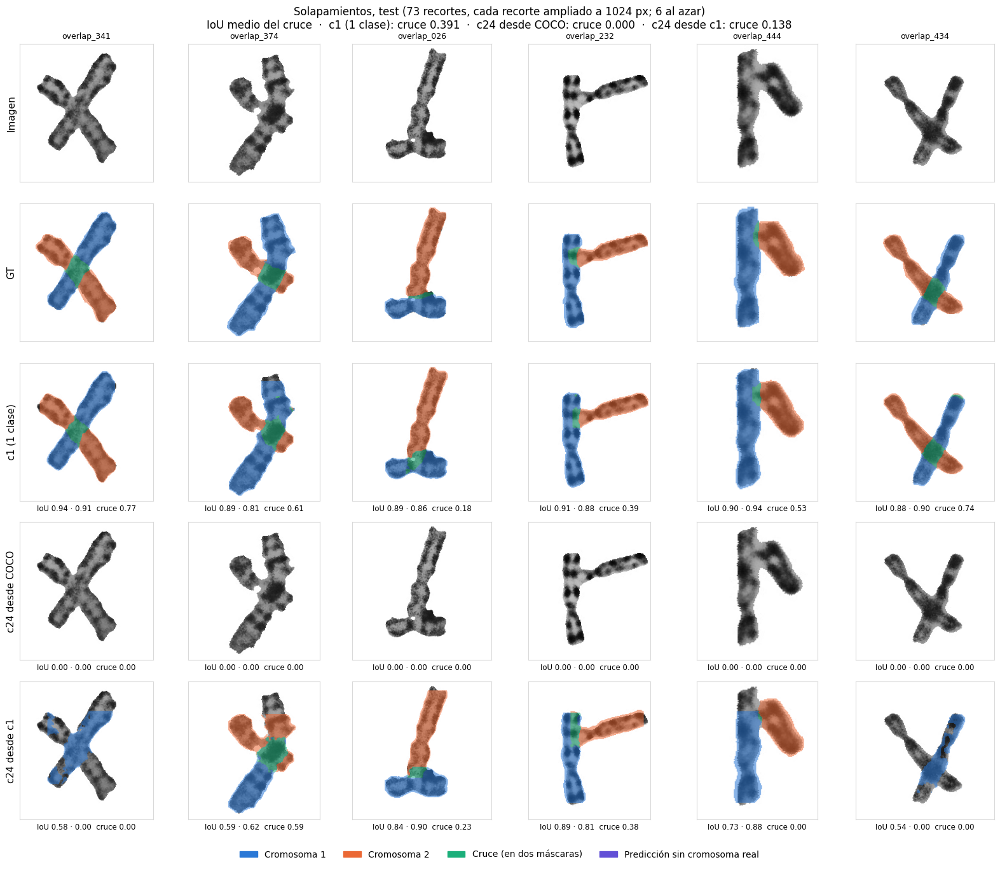

Guardada en /content/drive/MyDrive/yolo_runs/overlap_compare_recortes_c24.png


In [ ]:
import csv, glob, os, random, shutil, subprocess
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from PIL import Image as PILImage, ImageDraw
from ultralytics import YOLO

MODELS = {  # nombre -> pesos; los que todavía no existan se omiten
    'c1 (1 clase)': f'{RUNS_DIR}/chromosome1_yolo11s-seg_1024/weights/best.pt',
    'c24 desde COCO': f'{RUNS_DIR}/chromosome24_yolo11s-seg_1024/weights/best.pt',
    'c24 desde c1': f'{RUNS_DIR}/chromosome24_yolo11s-seg_1024_desde_c1/weights/best.pt',
}
MODE = 'recortes'    # 'lienzos' o 'recortes'
# Una máscara por cromosoma aunque el modelo dude entre dos clases. Con 24 clases y sin esto pueden quedar dos
# máscaras sobre el mismo cromosoma (p. ej. una "21" y otra "22"), que aquí contarían como un cruce falso.
AGNOSTIC = True
N_SHOW = 6          # recortes en la figura
SHOW = 'azar'       # 'azar' o 'peores' (los de menor IoU con el primer modelo)
CONF = 0.25
MIN_CROSS = 0.02    # hay cruce si la zona compartida ocupa al menos el 2 % del cromosoma más pequeño
DRIVE_ROOT = '/content/drive/MyDrive'
TAG = 'c24'         # sufijo del nombre de la figura, para no sobrescribir las anteriores
COLOURS = ['#2a78d6', '#eb6834']  # cromosoma 1, cromosoma 2
CROSS, EXTRA = '#1baf7a', '#6250d6'


def find_in_drive(pattern):
    """Primer archivo o carpeta de Drive que encaje con pattern (hasta 4 carpetas de profundidad)."""
    for depth in range(5):
        hits = sorted(glob.glob(f'{DRIVE_ROOT}/{"*/" * depth}{pattern}'))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'No encuentro {pattern} en {DRIVE_ROOT}')


# Datos: solo hacen falta los 73 recortes de test, sus polígonos y (para 'lienzos') los lienzos de test.
# Se copian aparte, así no hay que reconstruir chromosome1 si la sesión está con chromosome24.
CROPS_DIR = f'{LOCAL_DATA}/overlap_test'
LBL_DIR = f'{LOCAL_DATA}/seg_labels/chromosome1/test'
CANVAS_DIR = f'{LOCAL_DATA}/overlap_canvases'
if not os.path.isdir(LBL_DIR):
    subprocess.run(['unzip', '-q', '-o', SEG_LABELS_EXACT, '-d', LOCAL_DATA], check=True)
if not glob.glob(f'{CROPS_DIR}/overlap_*'):
    os.makedirs(CROPS_DIR, exist_ok=True)
    local = f'{LOCAL_DATA}/chromosome1_seg/images/test'
    src = local if glob.glob(f'{local}/overlap_*') else find_in_drive('chromosome1/images/test')
    for f in glob.glob(f'{src}/overlap_*'):
        if not f.endswith('.npy'):
            shutil.copy(f, CROPS_DIR)
if MODE == 'lienzos' and not os.path.isdir(CANVAS_DIR):
    subprocess.run(['unzip', '-q', '-o', find_in_drive('overlap_canvases.zip'), '-d', LOCAL_DATA], check=True)


def rgb(h):
    return np.array([int(h[i:i + 2], 16) for i in (1, 3, 5)]) / 255


def mask_iou(a, b):
    union = (a | b).sum()
    return (a & b).sum() / union if union else 0.0


def overlay(img, masks, colours, cross):
    base = img / 255
    out = base.copy()
    for m, c in zip(masks, colours):
        out[m] = 0.45 * base[m] + 0.55 * rgb(c)
    out[cross] = 0.45 * base[cross] + 0.55 * rgb(CROSS)
    return out


def predict_masks(model, path):
    r = model.predict(path, imgsz=IMGSZ, conf=CONF, agnostic_nms=AGNOSTIC, retina_masks=True, verbose=False)[0]
    if r.masks is None:
        return []
    H, W = r.orig_shape
    return [m if m.shape == (H, W) else np.asarray(PILImage.fromarray(m).resize((W, H), PILImage.NEAREST))
            for m in r.masks.data.cpu().numpy() > 0.5]


def evaluate(gt, pred):
    """Empareja cada cromosoma real con la máscara predicha que más se le parece y mide los IoU."""
    ious = np.array([[mask_iou(g, p) for p in pred] for g in gt]).reshape(len(gt), len(pred))
    match = {}
    for v, j, i in sorted(((ious[j, i], j, i) for j in range(len(gt)) for i in range(len(pred))), reverse=True):
        if v > 0 and j not in match and i not in match.values():
            match[j] = i
    gt_cross = np.sum(gt, 0) >= 2
    pred_cross = np.sum(pred, 0) >= 2 if len(pred) >= 2 else np.zeros_like(gt_cross)
    share = gt_cross.sum() / min(g.sum() for g in gt)
    return dict(pred=pred, match=match, chrom=[ious[j, match[j]] if j in match else 0.0 for j in range(len(gt))],
                pred_cross=pred_cross, share=share,
                cross=mask_iou(gt_cross, pred_cross) if share >= MIN_CROSS else None)


models = {}
for name, path in MODELS.items():
    if os.path.exists(path):
        models[name] = YOLO(path)
    else:
        print(f'{name}: no existe {path}, se omite')
if not models:
    raise FileNotFoundError('Ninguno de los modelos de MODELS existe todavía')

# Recortes de test: imagen y polígonos del dataset de solapamientos
crops = {}
for path in sorted(f for f in glob.glob(f'{CROPS_DIR}/overlap_*') if not f.endswith('.npy')):
    stem = os.path.splitext(os.path.basename(path))[0]
    img = np.asarray(PILImage.open(path).convert('RGB'))
    H, W = img.shape[:2]
    gt = []
    for line in open(f'{LBL_DIR}/{stem}.txt'):
        p = np.array(line.split()[1:], float).reshape(-1, 2) * [W, H]
        m = PILImage.new('1', (W, H), 0)
        ImageDraw.Draw(m).polygon([tuple(q) for q in p], fill=1)
        gt.append(np.asarray(m))
    crops[stem] = dict(path=path, img=img, gt=gt, gt_cross=np.sum(gt, 0) >= 2)

results = {name: {} for name in models}
if MODE == 'lienzos':
    by_canvas = {}
    for row in csv.DictReader(open(f'{CANVAS_DIR}/placements.csv')):
        if row['split'] == 'test':
            by_canvas.setdefault(row['canvas'], []).append(row)
    for canvas, places in by_canvas.items():
        path = f'{CANVAS_DIR}/images/test/{canvas}.jpg'
        canvas_img = np.asarray(PILImage.open(path).convert('RGB'))
        masks = {name: predict_masks(model, path) for name, model in models.items()}
        for row in places:
            c = crops[row['crop']]
            x0, y0, w, h = (int(row[k]) for k in ('x0', 'y0', 'w', 'h'))
            assert (h, w) == c['img'].shape[:2], 'los lienzos de test deben tener los recortes a escala 1'
            c['img'] = canvas_img[y0:y0 + h, x0:x0 + w]  # el recorte tal como lo ve el modelo en el lienzo
            for name in models:
                # Una máscara es de este recorte si al menos la mitad de sus píxeles cae dentro de su región
                pred = [m[y0:y0 + h, x0:x0 + w] for m in masks[name]]
                pred = [r for m, r in zip(masks[name], pred) if r.any() and r.sum() >= 0.5 * m.sum()]
                results[name][row['crop']] = evaluate(c['gt'], pred)
else:
    for stem, c in crops.items():
        for name, model in models.items():
            results[name][stem] = evaluate(c['gt'], predict_masks(model, c['path']))

# Resumen por modelo; el cruce también por tamaño (qué parte del cromosoma más pequeño queda dentro del cruce)
SIZES = [('<10 %', 0, 0.1), ('10-20 %', 0.1, 0.2), ('>=20 %', 0.2, 2)]
print(f'\n{len(crops)} recortes de test, modo {MODE}, NMS {"sin" if AGNOSTIC else "por"} clase')
print(f'{"modelo":16s} {"IoU crom.":>9s} {"IoU cruce":>9s} ' + ' '.join(f'{"cruce " + s:>13s}' for s, _, _ in SIZES) +
      f' {"cruce (píxeles juntos)":>23s}   nº máscaras igual/menos/más que el GT')
for name, res in results.items():
    rs = [(crops[s], r) for s, r in res.items()]
    chrom = np.mean([v for _, r in rs for v in r['chrom']])
    cross = [r['cross'] for _, r in rs if r['cross'] is not None]
    by_size = []
    for _, lo, hi in SIZES:
        sel = [r['cross'] for _, r in rs if r['cross'] is not None and lo <= r['share'] < hi]
        by_size.append(f'{np.mean(sel):.3f} ({len(sel):2d})' if sel else '-')
    pooled = (sum((c['gt_cross'] & r['pred_cross']).sum() for c, r in rs) /
              max(sum((c['gt_cross'] | r['pred_cross']).sum() for c, r in rs), 1))
    n_eq = sum(len(r['pred']) == len(c['gt']) for c, r in rs)
    n_less = sum(len(r['pred']) < len(c['gt']) for c, r in rs)
    print(f'{name:16s} {chrom:9.3f} {np.mean(cross):9.3f} ' + ' '.join(f'{s:>13s}' for s in by_size) +
          f' {pooled:23.3f}   {n_eq}/{n_less}/{len(rs) - n_eq - n_less}')

# Figura: imagen, GT y una fila por modelo
names = list(results)
score = lambda stem: np.mean(results[names[0]][stem]['chrom'] + ([results[names[0]][stem]['cross']]
                                                                 if results[names[0]][stem]['cross'] is not None else []))
random.seed(0)
shown = (sorted(crops, key=score) if SHOW == 'peores' else random.sample(list(crops), len(crops)))[:N_SHOW]
fig, axes = plt.subplots(2 + len(names), len(shown), figsize=(2.7 * len(shown), 2.75 * (2 + len(names))),
                         squeeze=False)
for col, stem in enumerate(shown):
    c = crops[stem]
    panels = [c['img'] / 255, overlay(c['img'], c['gt'], COLOURS, c['gt_cross'])]
    for name in names:
        r = results[name][stem]
        owner = {i: j for j, i in r['match'].items()}
        panels.append(overlay(c['img'], r['pred'], [COLOURS[owner[i]] if i in owner else EXTRA
                                                    for i in range(len(r['pred']))], r['pred_cross']))
    for ax, panel in zip(axes[:, col], panels):
        ax.imshow(panel)
        ax.set_xticks([])
        ax.set_yticks([])
        for s in ax.spines.values():
            s.set_color('0.85')
    axes[0, col].set_title(stem, fontsize=9)
    for ax, name in zip(axes[2:, col], names):
        r = results[name][stem]
        txt = ' · '.join(f'{v:.2f}' for v in r['chrom'])
        txt += f'  cruce {r["cross"]:.2f}' if r['cross'] is not None else ''
        ax.set_xlabel(f'IoU {txt}', fontsize=8.5)
for ax, label in zip(axes[:, 0], ['Imagen', 'GT'] + names):
    ax.set_ylabel(label, fontsize=11)
fig.legend(handles=[Patch(color=COLOURS[0], label='Cromosoma 1'), Patch(color=COLOURS[1], label='Cromosoma 2'),
                    Patch(color=CROSS, label='Cruce (en dos máscaras)'),
                    Patch(color=EXTRA, label='Predicción sin cromosoma real')],
           loc='lower center', ncol=4, frameon=False, fontsize=10, bbox_to_anchor=(0.5, -0.005))
summary = '  ·  '.join(f'{n}: cruce {np.mean([r["cross"] for r in results[n].values() if r["cross"] is not None]):.3f}'
                       for n in names)
where = 'a tamaño real en lienzos de 1024 px' if MODE == 'lienzos' else 'cada recorte ampliado a 1024 px'
fig.suptitle(f'Solapamientos, test ({len(crops)} recortes, {where}; '
             f'{"los " + str(len(shown)) + " peores del primer modelo" if SHOW == "peores" else str(len(shown)) + " al azar"})'
             f'\nIoU medio del cruce  ·  {summary}', fontsize=12)
plt.tight_layout(rect=(0, 0.025, 1, 1))
out = f'{RUNS_DIR}/overlap_compare_{MODE}_{TAG}.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print('Guardada en', out)

10/75 metafases
20/75 metafases
30/75 metafases
40/75 metafases
50/75 metafases
60/75 metafases
75/75 metafases

Cruces (zona compartida >= 10% del cromosoma más pequeño): 102 pares en 48 metafases
modelo               IoU crom.  separados  fusionados  IoU cruce  cruce (píxeles juntos)
c1 (1 clase)             0.826      96.1%        3.9%      0.603                   0.644
c24 desde COCO           0.782      93.1%       10.8%      0.482                   0.511
c24 desde c1             0.816      95.1%        4.9%      0.585                   0.639

Contactos (zona compartida 2%-10% del cromosoma más pequeño): 249 pares en 64 metafases
modelo               IoU crom.  separados  fusionados
c1 (1 clase)             0.848      96.4%        4.0%
c24 desde COCO           0.842      98.0%        4.4%
c24 desde c1             0.855      98.0%        2.0%

separados = los dos cromosomas del par encontrados con IoU >= 0.5; fusionados = una sola máscara se parece más a los dos juntos que a cualqu

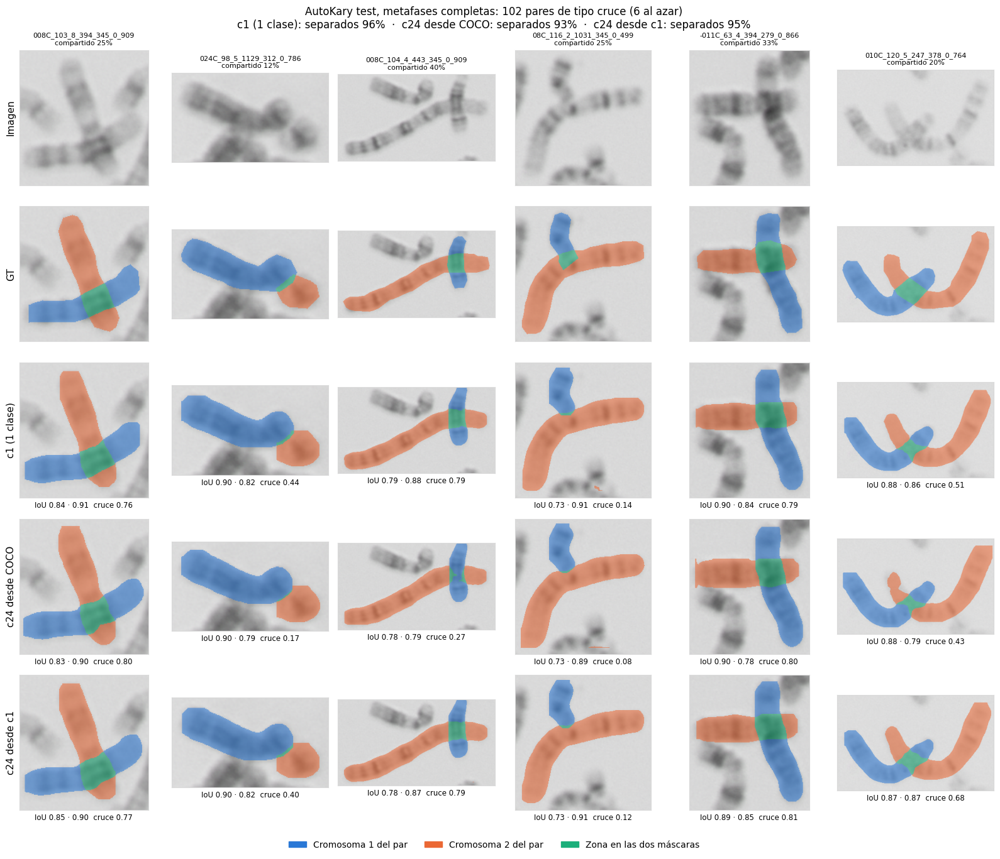

Guardada en /content/drive/MyDrive/yolo_runs/autokary_pares_cruce_c24.png


In [ ]:
# Cruces en metafases reales: pares de cromosomas de AutoKary (test, polígonos dibujados a mano) que se superponen.
# Cada metafase completa pasa por el modelo, como en uso real; luego se mira cómo quedó cada par.
# Versión para comparar los modelos de 24 clases con el de 1 clase: solo se miran las máscaras, no la clase.
#   cruce:    la zona compartida es >= 10 % del cromosoma más pequeño (uno pasa por encima del otro)
#   contacto: entre 2 y 10 % (se tocan; el solape es sobre todo del trazado a mano)
import glob, os, random
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from PIL import Image as PILImage, ImageDraw
from ultralytics import YOLO

MODELS = {  # nombre -> pesos; los que todavía no existan se omiten
    'c1 (1 clase)': f'{RUNS_DIR}/chromosome1_yolo11s-seg_1024/weights/best.pt',
    'c24 desde COCO': f'{RUNS_DIR}/chromosome24_yolo11s-seg_1024/weights/best.pt',
    'c24 desde c1': f'{RUNS_DIR}/chromosome24_yolo11s-seg_1024_desde_c1/weights/best.pt',
}
CROSS_MIN, CONTACT_MIN = 0.10, 0.02
SHOW_KIND = 'cruce'   # qué pares se dibujan: 'cruce' o 'contacto'
N_SHOW = 6
SHOW = 'azar'         # 'azar' o 'peores' (los de menor IoU con el primer modelo)
CONF = 0.1
# Una máscara por cromosoma aunque el modelo dude entre dos clases. Con 24 clases y sin esto pueden quedar dos
# máscaras sobre el mismo cromosoma (p. ej. una "21" y otra "22"), que aquí contarían como un cruce falso.
AGNOSTIC = True
MARGIN = 12           # px alrededor del par en la figura
TAG = 'c24'         # sufijo del nombre de la figura, para no sobrescribir las anteriores
# Metafases de test de AutoKary con sus polígonos: sirven las de chromosome24_seg o las de chromosome1_seg (son las
# mismas imágenes y los mismos polígonos; aquí no se usa la clase)
CROPS_DIR = next((d for d in (f'{LOCAL_DATA}/chromosome24_seg', f'{LOCAL_DATA}/chromosome1_seg')
                  if glob.glob(f'{d}/images/test/autokary_*')), None)
if CROPS_DIR is None:
    raise RuntimeError("Faltan los datos: ejecuta antes la celda 'Copiar el dataset' con TASK='segment'")
COLOURS = ['#2a78d6', '#eb6834']  # cromosoma 1, cromosoma 2 del par
CROSS = '#1baf7a'


def rgb(h):
    return np.array([int(h[i:i + 2], 16) for i in (1, 3, 5)]) / 255


def overlay(img, masks, colours, cross):
    base = img / 255
    out = base.copy()
    for m, c in zip(masks, colours):
        out[m] = 0.45 * base[m] + 0.55 * rgb(c)
    out[cross] = 0.45 * base[cross] + 0.55 * rgb(CROSS)
    return out


def box_of(m):
    ys, xs = np.flatnonzero(m.any(1)), np.flatnonzero(m.any(0))
    return (xs[0], ys[0], xs[-1] + 1, ys[-1] + 1) if len(xs) else (0, 0, 0, 0)


def touch(a, b):
    return a[0] < b[2] and b[0] < a[2] and a[1] < b[3] and b[1] < a[3]


def union_box(*boxes):
    boxes = [b for b in boxes if b[2] > b[0]]
    return min(b[0] for b in boxes), min(b[1] for b in boxes), max(b[2] for b in boxes), max(b[3] for b in boxes)


def mask_iou(a, b):
    union = (a | b).sum()
    return (a & b).sum() / union if union else 0.0


def iou_in(a, b, box):
    x0, y0, x1, y1 = box
    return mask_iou(a[y0:y1, x0:x1], b[y0:y1, x0:x1])


models = {}
for name, path in MODELS.items():
    if os.path.exists(path):
        models[name] = YOLO(path)
    else:
        print(f'{name}: no existe {path}, se omite')
if not models:
    raise FileNotFoundError('Ninguno de los modelos de MODELS existe todavía')

imgs = sorted(f for f in glob.glob(f'{CROPS_DIR}/images/test/autokary_*') if not f.endswith('.npy'))
pairs = []  # un dict por par, con los resultados de cada modelo
for n, path in enumerate(imgs, 1):
    stem = os.path.splitext(os.path.basename(path))[0]
    img = np.asarray(PILImage.open(path).convert('RGB'))
    H, W = img.shape[:2]
    gt = []
    for line in open(f'{CROPS_DIR}/labels/test/{stem}.txt'):
        p = np.array(line.split()[1:], float).reshape(-1, 2) * [W, H]
        m = PILImage.new('1', (W, H), 0)
        ImageDraw.Draw(m).polygon([tuple(q) for q in p], fill=1)
        gt.append(np.asarray(m))
    gbox = [box_of(g) for g in gt]
    area = [g.sum() for g in gt]
    found = []
    for i in range(len(gt)):
        for j in range(i + 1, len(gt)):
            if touch(gbox[i], gbox[j]):
                share = (gt[i] & gt[j]).sum() / min(area[i], area[j])
                if share >= CONTACT_MIN:
                    found.append((i, j, share))
    if not found:
        continue

    preds = {}
    for name, model in models.items():
        r = model.predict(path, imgsz=IMGSZ, conf=CONF, agnostic_nms=AGNOSTIC, retina_masks=True, verbose=False)[0]
        pm = [] if r.masks is None else [
            m if m.shape == (H, W) else np.asarray(PILImage.fromarray(m).resize((W, H), PILImage.NEAREST))
            for m in r.masks.data.cpu().numpy() > 0.5]
        pbox = [box_of(m) for m in pm]
        # Cada cromosoma real de la metafase se empareja con la máscara que más se le parece (IoU, de mayor a menor)
        cand = sorted(((iou_in(gt[g], pm[p], union_box(gbox[g], pbox[p])), g, p) for g in range(len(gt))
                       for p in range(len(pm)) if touch(gbox[g], pbox[p])), reverse=True)
        match, used = {}, set()
        for v, g, p in cand:
            if v > 0 and g not in match and p not in used:
                match[g] = (p, v)
                used.add(p)
        preds[name] = (pm, pbox, match)

    for i, j, share in found:
        x0, y0, x1, y1 = union_box(gbox[i], gbox[j])
        x0, y0, x1, y1 = max(0, x0 - MARGIN), max(0, y0 - MARGIN), min(W, x1 + MARGIN), min(H, y1 + MARGIN)
        crop = lambda m: m[y0:y1, x0:x1]
        pair = dict(stem=stem, i=i, j=j, kind='cruce' if share >= CROSS_MIN else 'contacto', share=share, img=crop(img),
                    gt=[crop(gt[i]), crop(gt[j])], gt_cross=crop(gt[i] & gt[j]), res={})
        for name, (pm, pbox, match) in preds.items():
            mi, mj = match.get(i), match.get(j)
            chrom = [mi[1] if mi else 0.0, mj[1] if mj else 0.0]
            # Fusionados: una sola máscara se parece más a los dos cromosomas juntos que a cualquiera de los dos
            # (dentro de la caja del par, que contiene a los dos cromosomas enteros)
            bx0, by0, bx1, by1 = union_box(gbox[i], gbox[j])
            gi, gj = gt[i][by0:by1, bx0:bx1], gt[j][by0:by1, bx0:bx1]
            merged = False
            for m, b in zip(pm, pbox):
                if touch(b, gbox[i]) and touch(b, gbox[j]):
                    mc = m[by0:by1, bx0:bx1]
                    both = mask_iou(mc, gi | gj)
                    if both >= 0.5 and both > max(mask_iou(mc, gi), mask_iou(mc, gj)):
                        merged = True
                        break
            cross = None
            if pair['kind'] == 'cruce':
                p_cross = pm[mi[0]] & pm[mj[0]] if mi and mj else np.zeros_like(gt[i])
                boxes = [gbox[i], gbox[j]] + [pbox[m[0]] for m in (mi, mj) if m]
                cross = iou_in(gt[i] & gt[j], p_cross, union_box(*boxes))
            shown = [crop(pm[m[0]]) if m else np.zeros_like(pair['gt'][0]) for m in (mi, mj)]
            pair['res'][name] = dict(chrom=chrom, merged=merged, cross=cross, pred=shown,
                                     pred_cross=shown[0] & shown[1])
        pairs.append(pair)
    if n % 10 == 0 or n == len(imgs):
        print(f'{n}/{len(imgs)} metafases', flush=True)

# Resumen por modelo
for kind, extra in (('cruce', True), ('contacto', False)):
    sel = [p for p in pairs if p['kind'] == kind]
    if not sel:
        continue
    lo = f'>= {CROSS_MIN:.0%}' if kind == 'cruce' else f'{CONTACT_MIN:.0%}-{CROSS_MIN:.0%}'
    print(f'\n{kind.capitalize()}s (zona compartida {lo} del cromosoma más pequeño): {len(sel)} pares en '
          f'{len({p["stem"] for p in sel})} metafases')
    print(f'{"modelo":20s} {"IoU crom.":>9s} {"separados":>10s} {"fusionados":>11s}' +
          (f' {"IoU cruce":>10s} {"cruce (píxeles juntos)":>23s}' if extra else ''))
    for name in models:
        rs = [p['res'][name] for p in sel]
        chrom = np.mean([v for r in rs for v in r['chrom']])
        separated = np.mean([min(r['chrom']) >= 0.5 for r in rs])  # los dos cromosomas encontrados con IoU >= 0.5
        merged = np.mean([r['merged'] for r in rs])
        line = f'{name:20s} {chrom:9.3f} {separated:10.1%} {merged:11.1%}'
        if extra:
            pooled = (sum((p['gt_cross'] & p['res'][name]['pred_cross']).sum() for p in sel) /
                      max(sum((p['gt_cross'] | p['res'][name]['pred_cross']).sum() for p in sel), 1))
            line += f' {np.mean([r["cross"] for r in rs]):10.3f} {pooled:23.3f}'
        print(line)
print('\nseparados = los dos cromosomas del par encontrados con IoU >= 0.5; '
      'fusionados = una sola máscara se parece más a los dos juntos que a cualquiera de ellos')

# Figura: pares del tipo SHOW_KIND; imagen, GT y una fila por modelo
names = list(models)
sel = [p for p in pairs if p['kind'] == SHOW_KIND]
score = lambda p: np.mean(p['res'][names[0]]['chrom'] + ([p['res'][names[0]]['cross']]
                                                         if p['res'][names[0]]['cross'] is not None else []))
if not sel:
    raise ValueError(f'No hay pares de tipo {SHOW_KIND!r} para dibujar')
random.seed(0)
shown = (sorted(sel, key=score) if SHOW == 'peores' else random.sample(sel, len(sel)))[:N_SHOW]
fig, axes = plt.subplots(2 + len(names), len(shown), figsize=(2.7 * len(shown), 2.75 * (2 + len(names))),
                         squeeze=False)
for col, p in enumerate(shown):
    panels = [p['img'] / 255, overlay(p['img'], p['gt'], COLOURS, p['gt_cross'])]
    panels += [overlay(p['img'], p['res'][n]['pred'], COLOURS, p['res'][n]['pred_cross']) for n in names]
    for ax, panel in zip(axes[:, col], panels):
        ax.imshow(panel)
        ax.set_xticks([])
        ax.set_yticks([])
        for s in ax.spines.values():
            s.set_color('0.85')
    axes[0, col].set_title(f'{p["stem"][-24:]}\ncompartido {p["share"]:.0%}', fontsize=8)
    for ax, name in zip(axes[2:, col], names):
        r = p['res'][name]
        txt = ' · '.join(f'{v:.2f}' for v in r['chrom'])
        txt += f'  cruce {r["cross"]:.2f}' if r['cross'] is not None else ''
        ax.set_xlabel(f'IoU {txt}' + ('\nfusionados' if r['merged'] else ''), fontsize=8.5)
for ax, label in zip(axes[:, 0], ['Imagen', 'GT'] + names):
    ax.set_ylabel(label, fontsize=11)
fig.legend(handles=[Patch(color=COLOURS[0], label='Cromosoma 1 del par'),
                    Patch(color=COLOURS[1], label='Cromosoma 2 del par'),
                    Patch(color=CROSS, label='Zona en las dos máscaras')],
           loc='lower center', ncol=3, frameon=False, fontsize=10, bbox_to_anchor=(0.5, -0.005))
summary = '  ·  '.join(
    f'{n}: separados {np.mean([min(p["res"][n]["chrom"]) >= 0.5 for p in sel]):.0%}' for n in names)
fig.suptitle(f'AutoKary test, metafases completas: {len(sel)} pares de tipo {SHOW_KIND} '
             f'({"los " + str(len(shown)) + " peores del primer modelo" if SHOW == "peores" else str(len(shown)) + " al azar"})'
             f'\n{summary}', fontsize=12)
plt.tight_layout(rect=(0, 0.025, 1, 1))
out = f'{RUNS_DIR}/autokary_pares_{SHOW_KIND}_{TAG}.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print('Guardada en', out)


In [ ]:
# Mismo modelo, solo las 75 metafases de AutoKary (máscaras a mano), con el detalle por clase
import glob, re
SEG24 = f'{LOCAL_DATA}/chromosome24_seg'
ak = sorted(f for f in glob.glob(f'{SEG24}/images/test/autokary_*') if not f.endswith('.npy'))
with open(f'{SEG24}/test_autokary.txt', 'w') as fh:
    fh.write('\n'.join(ak) + '\n')
with open(f'{SEG24}/data_colab.yaml') as fh:
    yaml_ak = re.sub(r'(?m)^test:.*$', f'test: {SEG24}/test_autokary.txt', fh.read())
with open(f'{SEG24}/data_autokary.yaml', 'w') as fh:
    fh.write(yaml_ak)
m = best.val(data=f'{SEG24}/data_autokary.yaml', split='test', imgsz=IMGSZ, batch=BATCH,
             project=RUNS_DIR, name=f'{RUN_NAME}_test_autokary', exist_ok=True)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO11s-seg summary (fused): 113 layers, 10,076,104 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3610.7±926.7 MB/s, size: 2287.6 KB)
val: Scanning /content/data/chromosome24_seg/labels/test... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 69.2it/s 1.1s
val: New cache created: /content/data/chromosome24_seg/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.0s/it 7.8s
                   all         75       3208      0.945      0.914      0.957      0.806      0.944      0.915      0.958      0.731
                     1         74        147      0.986      0.986      0.995      0.924      0.979       0.98      0.994      0.787
                     2         75        140      0.986      0.976      0.991      0.

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO11s-seg summary (fused): 113 layers, 10,076,104 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3478.0±210.7 MB/s, size: 2371.0 KB)
val: Scanning /content/data/chromosome24_seg/labels/test.cache... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 22.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.7s/it 6.8s
                   all         75       3208      0.946      0.918      0.921      0.779      0.947      0.918      0.922      0.708
                     1         74        147      0.991      0.986      0.995      0.924      0.984       0.98      0.995      0.787
                     2         75        140      0.986      0.979      0.971      0.903      0.964      0.957      0.951      0.766
                  

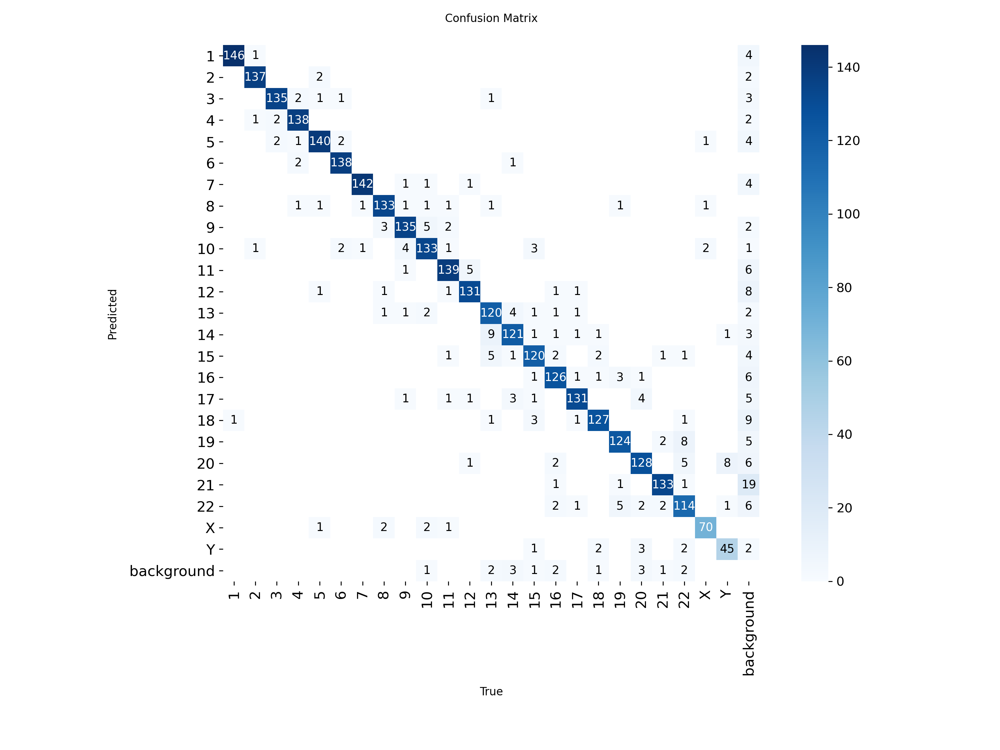

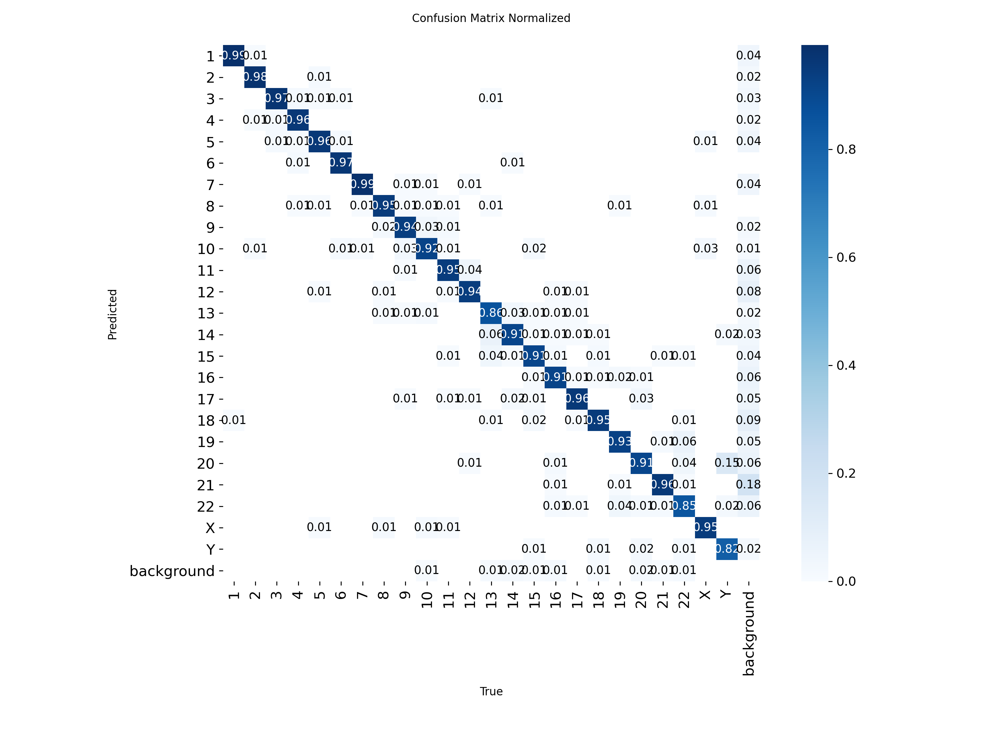

Confusiones más frecuentes (real → predicho):
  13 → 14     9  (0.065 de los 13)
   Y → 20     8  (0.145 de los Y)
  22 → 19     8  (0.060 de los 22)
  22 → 20     5  (0.037 de los 22)
  19 → 22     5  (0.037 de los 19)
  13 → 15     5  (0.036 de los 13)
  12 → 11     5  (0.036 de los 12)
  10 → 9      5  (0.034 de los 10)
  20 → 17     4  (0.028 de los 20)
  14 → 13     4  (0.030 de los 14)
No detectados: 16 de 3208  ·  detecciones sin cromosoma real: 103


In [ ]:
# Matriz de confusión de Ultralytics para el c24 desde c1, test de AutoKary (máscaras a mano)
# conf=0.1: no se pierden los cromosomas de clase dudosa. agnostic_nms=True: una sola clase por cromosoma
# (Ultralytics evalúa con varias clases por caja y, sin esto, un cromosoma puede contar como "21" y como "22").
# En la figura de Ultralytics las columnas son la clase real y las filas la predicha; en la normalizada cada columna suma 1.
import glob, re
from IPython.display import Image, display

SEG24 = f'{LOCAL_DATA}/chromosome24_seg'
ak = sorted(f for f in glob.glob(f'{SEG24}/images/test/autokary_*') if not f.endswith('.npy'))
with open(f'{SEG24}/test_autokary.txt', 'w') as fh:
    fh.write('\n'.join(ak) + '\n')
with open(f'{SEG24}/data_colab.yaml') as fh:
    yaml_ak = re.sub(r'(?m)^test:.*$', f'test: {SEG24}/test_autokary.txt', fh.read())
with open(f'{SEG24}/data_autokary.yaml', 'w') as fh:
    fh.write(yaml_ak)

m = best.val(data=f'{SEG24}/data_autokary.yaml', split='test', imgsz=IMGSZ, batch=BATCH, conf=0.1,
             agnostic_nms=True, plots=True, project=RUNS_DIR, name=f'{RUN_NAME}_cm_autokary', exist_ok=True)
for f in sorted(glob.glob(f'{m.save_dir}/confusion_matrix*.png')):
    display(Image(filename=f, width=900))

# Las confusiones más frecuentes, en texto (matriz de Ultralytics: filas = predicho, columnas = real)
cmx = m.confusion_matrix.matrix
names = [best.names[i] for i in range(len(best.names))]
nc = len(names)
real = cmx[:, :nc].sum(0)
off = sorted(((cmx[p, t], t, p) for t in range(nc) for p in range(nc) if p != t and cmx[p, t]), reverse=True)
print('Confusiones más frecuentes (real → predicho):')
for n, t, p in off[:10]:
    print(f'  {names[t]:>2} → {names[p]:<2}  {int(n):4d}  ({n / real[t]:.3f} de los {names[t]})')
print(f'No detectados: {int(cmx[nc, :nc].sum())} de {int(real.sum())}  ·  '
      f'detecciones sin cromosoma real: {int(cmx[:nc, nc].sum())}')

In [ ]:
import numpy as np
from ultralytics import YOLO

SEG24 = f'{LOCAL_DATA}/chromosome24_seg'   # data_autokary.yaml lo creó la celda anterior
for label, run in (('Desde COCO', 'chromosome24_yolo11s-seg_1024'),
                   ('Desde c1', 'chromosome24_yolo11s-seg_1024_desde_c1')):
    mm = YOLO(f'{RUNS_DIR}/{run}/weights/best.pt').val(
        data=f'{SEG24}/data_autokary.yaml', split='test', imgsz=IMGSZ, batch=BATCH, conf=0.1, agnostic_nms=True,
        plots=True, verbose=False, project=RUNS_DIR, name=f'{run}_cm_autokary', exist_ok=True)
    c = mm.confusion_matrix.matrix
    d = c[:24, :24]
    print(f'{label:11s} bien clasificados {np.trace(d) / d.sum():.1%} · no detectados {int(c[24, :24].sum())} '
          f'· detecciones sin cromosoma real {int(c[:24, 24].sum())}')

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO11s-seg summary (fused): 113 layers, 10,076,104 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2878.7±841.0 MB/s, size: 2435.8 KB)
val: Scanning /content/data/chromosome24_seg/labels/test.cache... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 21.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.7s/it 6.9s
                   all         75       3208      0.938      0.925      0.923      0.762      0.939      0.925      0.924      0.699
Speed: 12.7ms preprocess, 5.3ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /content/drive/MyDrive/yolo_runs/chromosome24_yolo11s-seg_1024_cm_autokary
Desde COCO  bien clasificados 94.6% · no detectados 20 · detecciones sin cromosoma real 202
Ultralytics 8.4.1

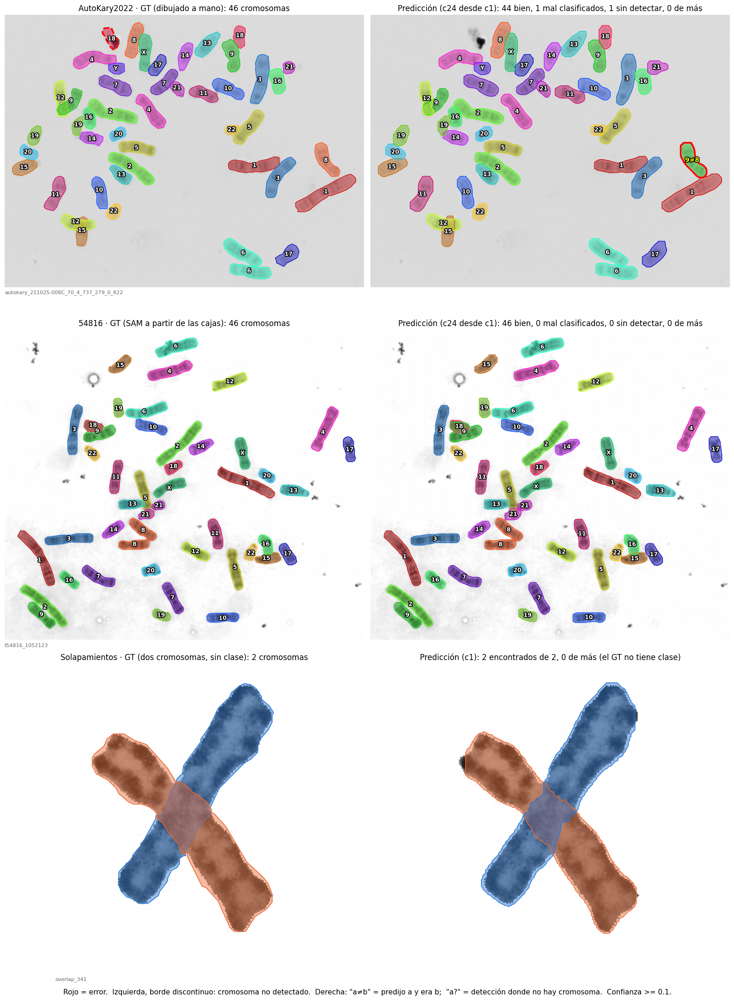

Guardada en /content/drive/MyDrive/yolo_runs/predicciones_c24_y_c1/tres_datasets.png
AutoKary2022: 10 predicciones en /content/drive/MyDrive/yolo_runs/predicciones_c24_y_c1/AutoKary2022
54816: 10 predicciones en /content/drive/MyDrive/yolo_runs/predicciones_c24_y_c1/54816
Solapamientos: 10 predicciones en /content/drive/MyDrive/yolo_runs/predicciones_c24_y_c1/Solapamientos


In [ ]:
# Predicciones en los tres datasets con dos modelos, cada uno donde funciona: las metafases completas con el de
# 24 clases (c24 desde c1) y los recortes de pocos cromosomas con c1 (1 clase), el único que se entrenó con ellos.
# El modelo se elige solo, por el tamaño de la imagen (CROP_MAX). GT a la izquierda, predicción a la derecha.
#   AutoKary2022:  GT dibujado a mano
#   54816:         GT = polígonos de SAM a partir de las cajas originales (no son máscaras dibujadas a mano)
#   Solapamientos: GT sin clase (el dataset solo marca los dos cromosomas)
# Además guarda en Drive las predicciones de SAVE_N imágenes de test de cada dataset, dibujadas por Ultralytics.
import colorsys, glob, os, random, shutil, subprocess
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Polygon
from PIL import Image as PILImage
from ultralytics import YOLO

MODELS = {  # tipo de imagen -> (nombre, pesos)
    'metafase': ('c24 desde c1', f'{RUNS_DIR}/chromosome24_yolo11s-seg_1024_desde_c1/weights/best.pt'),
    'recorte': ('c1', f'{RUNS_DIR}/chromosome1_yolo11s-seg_1024/weights/best.pt'),
}
CROP_MAX = 400      # lado mayor < 400 px = recorte (los de solapamientos miden 64-364 px; las metafases, 442 o más)
IMAGES = {  # una imagen de test por dataset; None = una al azar
    'AutoKary2022': 'autokary_211025-008C_70_4_737_279_0_822',
    '54816': None,
    'Solapamientos': 'overlap_341',
}
CONF = 0.1          # como en la evaluación de cruces: no se pierden los cromosomas de clase dudosa
SAVE_N = 10         # imágenes de test por dataset que se guardan dibujadas por Ultralytics (None = todas, 0 = ninguna)
SEED = 0
DRIVE_ROOT = '/content/drive/MyDrive'
SEG24 = f'{LOCAL_DATA}/chromosome24_seg'
OUT_DIR = f'{RUNS_DIR}/predicciones_c24_y_c1'
GT2 = ((0.16, 0.47, 0.84), (0.92, 0.41, 0.2))  # recortes de solapamientos: cromosoma 1 azul, cromosoma 2 naranja
EXTRA = (0.38, 0.31, 0.84)                     # predicción que no corresponde a ningún cromosoma real


def find_in_drive(pattern):
    """Primer archivo o carpeta de Drive que encaje con pattern (hasta 4 carpetas de profundidad)."""
    for depth in range(5):
        hits = sorted(glob.glob(f'{DRIVE_ROOT}/{"*/" * depth}{pattern}'))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'No encuentro {pattern} en {DRIVE_ROOT}')


# Datos: AutoKary y 54816 vienen de chromosome24_seg; los recortes de solapamientos solo están en chromosome1,
# así que se copian aparte (los 73 de test) con sus polígonos de seg_labels.zip
if not os.path.isdir(f'{SEG24}/labels/test'):
    raise RuntimeError("Falta chromosome24_seg: ejecuta antes la celda 'Copiar el dataset' con VARIANT='chromosome24', "
                       "TASK='segment'")
OV_DIR, OV_LBL = f'{LOCAL_DATA}/overlap_test', f'{LOCAL_DATA}/seg_labels/chromosome1/test'
if not os.path.isdir(OV_LBL):
    subprocess.run(['unzip', '-q', '-o', SEG_LABELS_EXACT, '-d', LOCAL_DATA], check=True)
if not glob.glob(f'{OV_DIR}/overlap_*'):
    os.makedirs(OV_DIR, exist_ok=True)
    local = f'{LOCAL_DATA}/chromosome1_seg/images/test'
    src = local if glob.glob(f'{local}/overlap_*') else find_in_drive('chromosome1/images/test')
    for f in glob.glob(f'{src}/overlap_*'):
        if not f.endswith('.npy'):
            shutil.copy(f, OV_DIR)

images = lambda d, prefix: sorted(f for f in glob.glob(f'{d}/{prefix}*') if not f.endswith('.npy'))
DATASETS = {  # nombre -> (imágenes de test, carpeta de etiquetas, ¿el GT tiene clase?)
    'AutoKary2022': (images(f'{SEG24}/images/test', 'autokary_'), f'{SEG24}/labels/test', True),
    '54816': (images(f'{SEG24}/images/test', 't54816'), f'{SEG24}/labels/test', True),
    'Solapamientos': (images(OV_DIR, 'overlap_'), OV_LBL, False),
}

loaded = {kind: (label, YOLO(path)) for kind, (label, path) in MODELS.items()}
NAMES = loaded['metafase'][1].names  # nombres de las 24 clases, para el GT de las metafases


def colour(k):
    """Un color por clase (el de las figuras anteriores): los dos cromosomas de un par lo comparten."""
    return colorsys.hsv_to_rgb((k * 7 % 24) / 24, 0.85, 1.0 if k % 2 else 0.8)


def box(p):
    return p[:, 0].min(), p[:, 1].min(), p[:, 0].max(), p[:, 1].max()


def mask_box(m):
    ys, xs = np.flatnonzero(m.any(1)), np.flatnonzero(m.any(0))
    return xs[0], ys[0], xs[-1] + 1, ys[-1] + 1


def iou(a, b):
    iw = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    ih = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)


def label_at(p, crop):
    """Dónde escribir la clase: en el centro, salvo en los recortes, donde en una X los dos centros caen en el cruce
    y las etiquetas se pisan; ahí va cerca del extremo superior de cada cromosoma."""
    if not crop:
        return p.mean(0)
    top = p[p[:, 1].argmin()]
    return top + 0.2 * (p.mean(0) - top)


def pred_colour(i, k, with_cls, match_p):
    """Color de la predicción i (clase k): el de su clase; sin clases (recortes de solapamientos), el del cromosoma
    real con el que se emparejó (azul o naranja, como en el GT)."""
    if with_cls:
        return colour(k)
    return GT2[match_p[i] % 2] if i in match_p else EXTRA


def predict(path):
    """Segmenta con el modelo que corresponde a la imagen: c1 si es un recorte, el de 24 clases si es una metafase."""
    kind = 'recorte' if max(PILImage.open(path).size) < CROP_MAX else 'metafase'
    label, model = loaded[kind]
    r = model.predict(path, imgsz=IMGSZ, conf=CONF, agnostic_nms=True, retina_masks=True, verbose=False)[0]
    return r, label, model.names


random.seed(SEED)
halo = [pe.withStroke(linewidth=2.5, foreground='black')]
fig, axes = plt.subplots(len(DATASETS), 2, figsize=(16, 7.2 * len(DATASETS)), squeeze=False)
for row, (name, (paths, lbl_dir, has_cls)) in enumerate(DATASETS.items()):
    path = next((p for p in paths if IMAGES.get(name) and os.path.splitext(os.path.basename(p))[0] == IMAGES[name]),
                None) or random.choice(paths)
    stem = os.path.splitext(os.path.basename(path))[0]
    img = np.asarray(PILImage.open(path).convert('RGB'))
    H, W = img.shape[:2]
    gt = []
    for line in open(f'{lbl_dir}/{stem}.txt'):
        v = line.split()
        gt.append((int(v[0]), np.array(v[1:], float).reshape(-1, 2) * [W, H]))
    r, model_label, names = predict(path)
    with_cls = has_cls and len(names) > 1  # las clases se comparan solo si el GT y el modelo las tienen
    # Máscaras tal cual (píxeles), no r.masks.xy: cuando una máscara tiene varios trozos, Ultralytics une todos sus
    # contornos en un solo polígono con rectas entre ellos y el dibujo sale deformado
    masks = [] if r.masks is None else [
        m if m.shape == (H, W) else np.asarray(PILImage.fromarray(m).resize((W, H), PILImage.NEAREST))
        for m in r.masks.data.cpu().numpy() > 0.5]
    pred = [(int(c), m, mask_box(m)) for c, m in zip(r.boxes.cls.tolist(), masks) if m.any()]

    # Emparejar cada predicción con un cromosoma real por solapamiento de cajas (IoU >= 0.5), de mayor a menor
    pairs = sorted(((iou(b, box(g)), i, j) for i, (_, _, b) in enumerate(pred) for j, (_, g) in enumerate(gt)),
                   reverse=True)
    match_p, match_g = {}, {}
    for v, i, j in pairs:
        if v < 0.5:
            break
        if i not in match_p and j not in match_g:
            match_p[i], match_g[j] = j, i
    missed, extra = len(gt) - len(match_g), len(pred) - len(match_p)
    if with_cls:
        ok = sum(pred[i][0] == gt[j][0] for i, j in match_p.items())
        result = f'{ok} bien, {len(match_p) - ok} mal clasificados, {missed} sin detectar, {extra} de más'
    else:
        result = f'{len(match_p)} encontrados de {len(gt)}, {extra} de más (el GT no tiene clase)'

    pts = np.concatenate([p for _, p in gt] + [np.reshape(b, (2, 2)) for _, _, b in pred])
    (x0, y0), (x1, y1) = np.maximum(pts.min(0) - 30, 0), np.minimum(pts.max(0) + 30, [W, H])  # zona con cromosomas
    # Predicción: cada máscara se tiñe con su color (donde se cruzan dos, se mezclan)
    shade = img / 255
    for i, (k, m, _) in enumerate(pred):
        shade[m] = 0.55 * shade[m] + 0.45 * np.array(pred_colour(i, k, with_cls, match_p))
    gt_title = {'AutoKary2022': 'GT (dibujado a mano)', '54816': 'GT (SAM a partir de las cajas)',
                'Solapamientos': 'GT (dos cromosomas, sin clase)'}[name]
    titles = [f'{name} · {gt_title}: {len(gt)} cromosomas', f'Predicción ({model_label}): {result}']
    for ax, title, base in zip(axes[row], titles, [img, shade]):
        ax.imshow(base)
        ax.set_xlim(x0, x1)
        ax.set_ylim(y1, y0)
        ax.axis('off')
        ax.set_title(title, fontsize=12)
    axes[row][0].text(0, -0.01, stem, transform=axes[row][0].transAxes, fontsize=8, color='0.4', va='top')
    fs = 9 if has_cls or H > 400 else 13  # los recortes de solapamientos son pequeños: etiquetas más grandes
    for j, (k, p) in enumerate(gt):
        lost = j not in match_g
        c = colour(k) if has_cls else GT2[j % 2]
        axes[row][0].add_patch(Polygon(p, closed=True, facecolor=(*c, 0.45), edgecolor='red' if lost else c,
                                       lw=2.5 if lost else 1.2, ls='--' if lost else '-'))
        if has_cls:
            axes[row][0].text(*p.mean(0), NAMES[k], color='white', fontsize=fs, ha='center', va='center',
                              weight='bold', path_effects=halo)
    for i, (k, m, (bx0, by0, bx1, by1)) in enumerate(pred):
        j = match_p.get(i)
        good = j is not None and (not with_cls or gt[j][0] == k)
        # Borde de la máscara (solo dentro de su caja, con 1 px de margen: más rápido que en toda la imagen)
        bx0, by0, bx1, by1 = max(bx0 - 1, 0), max(by0 - 1, 0), min(bx1 + 1, W), min(by1 + 1, H)
        axes[row][1].contour(np.arange(bx0, bx1), np.arange(by0, by1), m[by0:by1, bx0:bx1].astype(float),
                             levels=[0.5], colors=[pred_colour(i, k, with_cls, match_p) if good else 'red'],
                             linewidths=1.2 if good else 2.5)
        if len(names) == 1:  # modelo de 1 clase: no hay clase que escribir, solo se marca la detección de más
            txt = None if good else '?'
        else:
            txt = names[k] if good else f'{names[k]}≠{NAMES[gt[j][0]]}' if j is not None else f'{names[k]}?'
        if txt:
            axes[row][1].text(*label_at(np.argwhere(m)[:, ::-1].astype(float), not has_cls), txt,
                              color='white' if good else 'yellow', fontsize=fs if good else fs + 1,
                              ha='center', va='center', weight='bold', path_effects=halo)
plt.tight_layout()
fig.text(0.5, 0.0, 'Rojo = error.  Izquierda, borde discontinuo: cromosoma no detectado.  Derecha: "a≠b" = predijo a y '
         f'era b;  "a?" = detección donde no hay cromosoma.  Confianza >= {CONF}.', ha='center', va='top', fontsize=11)
os.makedirs(OUT_DIR, exist_ok=True)
out = f'{OUT_DIR}/tres_datasets.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print('Guardada en', out)

# Predicciones dibujadas por Ultralytics (cajas, máscaras, clase y confianza) para SAVE_N imágenes de cada dataset
if SAVE_N != 0:
    for name, (paths, _, _) in DATASETS.items():
        sel = paths if SAVE_N is None else random.Random(SEED).sample(paths, min(SAVE_N, len(paths)))
        os.makedirs(f'{OUT_DIR}/{name}', exist_ok=True)
        for path in sel:
            predict(path)[0].save(filename=f'{OUT_DIR}/{name}/{os.path.splitext(os.path.basename(path))[0]}.jpg')
        print(f'{name}: {len(sel)} predicciones en {OUT_DIR}/{name}')

In [ ]:
# Solo segmentación, sin mirar la clase, en el test de cada dataset. Con single_cls=True Ultralytics trata todos los
# cromosomas (reales y predichos) como una sola clase: mide si cada cromosoma tiene su máscara y qué tan bien encaja.
#   AutoKary2022:  75 metafases, máscaras dibujadas a mano
#   54816:         1250 metafases, máscaras de SAM a partir de las cajas (no dibujadas a mano)
#   Solapamientos: 73 recortes de dos cromosomas, ampliados a IMGSZ como en el entrenamiento de c1
import glob, os, re, shutil, subprocess
from ultralytics import YOLO

MODELS = {  # nombre -> carpeta del run en RUNS_DIR; los que todavía no existan se omiten
    'c1 (1 clase)': 'chromosome1_yolo11s-seg_1024',
    'c24 desde COCO': 'chromosome24_yolo11s-seg_1024',
    'c24 desde c1': 'chromosome24_yolo11s-seg_1024_desde_c1',
}
DRIVE_ROOT = '/content/drive/MyDrive'
SEG24 = f'{LOCAL_DATA}/chromosome24_seg'
EVAL_DIR = f'{LOCAL_DATA}/eval_seg'


def find_in_drive(pattern):
    """Primer archivo o carpeta de Drive que encaje con pattern (hasta 4 carpetas de profundidad)."""
    for depth in range(5):
        hits = sorted(glob.glob(f'{DRIVE_ROOT}/{"*/" * depth}{pattern}'))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'No encuentro {pattern} en {DRIVE_ROOT}')


if not os.path.isfile(f'{SEG24}/data_colab.yaml'):
    raise RuntimeError("Falta chromosome24_seg: ejecuta antes la celda 'Copiar el dataset' con VARIANT='chromosome24', "
                       "TASK='segment'")
with open(f'{SEG24}/data_colab.yaml') as fh:
    yaml24 = fh.read()

# Recortes de solapamientos: imágenes y polígonos en una carpeta images/ + labels/, como la espera Ultralytics
OV = f'{EVAL_DIR}/overlap'
if not glob.glob(f'{OV}/images/test/overlap_*'):
    for sub in ('images', 'labels'):
        os.makedirs(f'{OV}/{sub}/test', exist_ok=True)
    if not os.path.isdir(f'{LOCAL_DATA}/seg_labels/chromosome1/test'):
        subprocess.run(['unzip', '-q', '-o', SEG_LABELS_EXACT, '-d', LOCAL_DATA], check=True)
    local = f'{LOCAL_DATA}/chromosome1_seg/images/test'
    src = local if glob.glob(f'{local}/overlap_*') else find_in_drive('chromosome1/images/test')
    for f in glob.glob(f'{src}/overlap_*'):
        if not f.endswith('.npy'):
            shutil.copy(f, f'{OV}/images/test')
            stem = os.path.splitext(os.path.basename(f))[0]
            shutil.copy(f'{LOCAL_DATA}/seg_labels/chromosome1/test/{stem}.txt', f'{OV}/labels/test')


def subset_yaml(name, files):
    """data.yaml de chromosome24 con el test reducido a la lista de imágenes files."""
    with open(f'{EVAL_DIR}/{name}.txt', 'w') as fh:
        fh.write('\n'.join(files) + '\n')
    with open(f'{EVAL_DIR}/{name}.yaml', 'w') as fh:
        fh.write(re.sub(r'(?m)^test:.*$', f'test: {EVAL_DIR}/{name}.txt', yaml24))
    return f'{EVAL_DIR}/{name}.yaml'


images = lambda d, prefix: sorted(f for f in glob.glob(f'{d}/{prefix}*') if not f.endswith('.npy'))
SETS = {
    'AutoKary2022': subset_yaml('autokary', images(f'{SEG24}/images/test', 'autokary_')),
    '54816': subset_yaml('54816', images(f'{SEG24}/images/test', 't54816')),
    'Solapamientos': subset_yaml('overlap', images(f'{OV}/images/test', 'overlap_')),
}

rows = []
for label, run in MODELS.items():
    weights = f'{RUNS_DIR}/{run}/weights/best.pt'
    if not os.path.exists(weights):
        print(f'{label}: no existe {weights}, se omite')
        continue
    model = YOLO(weights)
    for dataset, yml in SETS.items():
        m = model.val(data=yml, split='test', imgsz=IMGSZ, batch=BATCH, single_cls=True, plots=False,
                      verbose=False, project=f'{RUNS_DIR}/eval_seg', name=f'{run}_{dataset}', exist_ok=True)
        rows.append((label, dataset, m.seg.mp, m.seg.mr, m.seg.map50, m.seg.map, m.box.map50, m.box.map))

print(f'\nSegmentación sin clase (single_cls), test de cada dataset')
print(f'{"modelo":16s} {"dataset":14s} {"P":>6s} {"R":>6s} {"máscaras mAP50":>15s} {"mAP50-95":>9s} '
      f'{"cajas mAP50":>12s} {"mAP50-95":>9s}')
for dataset in SETS:
    for label, d, p, r, s50, s, b50, b in rows:
        if d == dataset:
            print(f'{label:16s} {d:14s} {p:6.3f} {r:6.3f} {s50:15.3f} {s:9.3f} {b50:12.3f} {b:9.3f}')
    print()
print('54816: las máscaras de referencia son de SAM, no dibujadas a mano. '
      'Solapamientos: solo c1 se entrenó con este dataset.')

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4662.0±692.1 MB/s, size: 2363.9 KB)
val: Scanning /content/data/chromosome24_seg/labels/test... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 70.3it/s 1.1s
val: New cache created: /content/data/chromosome24_seg/labels/test.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.0s/it 4.2s
                   all         75       3208      0.977      0.985      0.992      0.847      0.975      0.983      0.992      0.763
Speed: 2.0ms preprocess, 4.3ms inference, 0.0ms loss, 1.4ms postprocess per image
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (N